# Final Project Deliverable: Detection and Longitudinal Evolution of AI-Generated Scientific Text 

**Course:** Deep Learning for Natural Language Processing (NLP)  
**Academic Semester:** 2026/2  
**Author:** Gustavo Freitas Cunha  

---

> **AI Disclosure and Academic Integrity Statement**  
> In accordance with institutional policies on the ethical use of Artificial Intelligence (https://www.ufmg.br/ia/), this deliverable documents the utilization of AI assistance:  
>  
> - **Agents Utilized:** Google Antigravity (agentic assistant powered by Gemini).  
> - **Scope of AI Assistance:** Used strictly for code boilerplate generation, documentation scaffolding, and syntax formatting.  
> - **Student Authorship and Oversight:** All conceptual formulations, architectural choices, experimental workflows, and analytical interpretations were designed and authored directly by me.  
> - **Validation:** Every pipeline component and result was reviewed, compiled, and validated by me in the runtime environment.

# 1. Setup & Environment

In this section, I install required NLP dependencies, centralize scientific module imports, fix deterministic seeds for experimental reproducibility, and inspect the runtime hardware accelerator (Nvidia Tesla T4 GPU on Google Colab).

In [26]:
#CELL 1.1 - INSTALL REQUIRED LIBRARIES AND NLP DEPENDENCIES
%pip install -q transformers datasets evaluate scikit-learn scipy optuna spacy torch matplotlib seaborn pandas numpy
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [27]:
#CELL 1.2 - IMPORT LIBRARIES AND CONFIGURE REPRODUCIBILITY ENVIRONMENT
import os
import re
import sys
import gc
import math
import json
import gzip
import urllib.request
import time
import random
import inspect
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any, Set
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.feature_selection import mutual_info_classif
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import transformers
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed,
)

import spacy
import optuna

#configure deterministic random seeds across libraries
GLOBAL_SEED = 42

def configure_environment(seed: int = GLOBAL_SEED) -> None:
    #fix random seeds for scientific reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

configure_environment(GLOBAL_SEED)

#standardized colorblind safe palette across all figures
HUMAN_COLOR = "#3D6B82"
AI_COLOR = "#E06C75"
CLASS_PALETTE = {"Human": HUMAN_COLOR, "AI": AI_COLOR}

#configure clean sans serif visual style
plt.style.use("default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Liberation Sans", "Arial", "Helvetica"],
    "font.size": 10.5,
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.9,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.0,
    "legend.framealpha": 0.92,
    "figure.titlesize": 13.5,
    "figure.dpi": 150,
})

def style_clean_axis(ax: Any, rotate_xticks: int = 0) -> None:
    """Apply clean four-sided border and subtle gridlines to a Matplotlib axis."""
    ax.set_facecolor("white")
    for spine in ("top", "right", "bottom", "left"):
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_color("#333333")
        ax.spines[spine].set_linewidth(0.85)
    ax.grid(True, which="major", color="#E2E2E2", linestyle="-", linewidth=0.6)
    ax.set_axisbelow(True)
    if rotate_xticks:
        ax.tick_params(axis="x", rotation=rotate_xticks)

print(f"Reproducibility environment configured successfully with random seed {GLOBAL_SEED}.")

Reproducibility environment configured successfully with random seed 42.


In [28]:
#CELL 1.3 - INSPECT RUNTIME ACCELERATOR AND ENVIRONMENT CONFIGURATION
def inspect_hardware_environment() -> Dict[str, Any]:
    #query system platform cuda driver and available gpu resources
    has_cuda = torch.cuda.is_available()
    device_name = torch.cuda.get_device_name(0) if has_cuda else "CPU (No CUDA Accelerator)"
    device_count = torch.cuda.device_count() if has_cuda else 0
    total_memory_gb = (
        torch.cuda.get_device_properties(0).total_memory / (1024 ** 3) if has_cuda else 0.0
    )

    environment_info = {
        "python_version": sys.version.split()[0],
        "torch_version": torch.__version__,
        "transformers_version": transformers.__version__,
        "cuda_available": has_cuda,
        "device_name": device_name,
        "device_count": device_count,
        "total_memory_gb": round(total_memory_gb, 2),
    }

    print("=" * 70)
    print("RUNTIME HARDWARE ACCELERATOR INSPECTION")
    print(f"Python Version:       {environment_info['python_version']}")
    print(f"PyTorch Version:      {environment_info['torch_version']}")
    print(f"Transformers Version: {environment_info['transformers_version']}")
    print(f"CUDA Available:       {environment_info['cuda_available']}")
    print(f"Device Name:          {environment_info['device_name']}")
    print(f"Device Count:         {environment_info['device_count']}")
    if has_cuda:
        print(f"VRAM Capacity:        {environment_info['total_memory_gb']} GB")
    print("=" * 70)
    return environment_info

_ = inspect_hardware_environment()

RUNTIME HARDWARE ACCELERATOR INSPECTION
Python Version:       3.13.18
PyTorch Version:      2.14.1+cpu
Transformers Version: 5.22.1
CUDA Available:       False
Device Name:          CPU (No CUDA Accelerator)
Device Count:         0


# 2. Data Acquisition & Corpus Overview

This section establishes the empirical foundation for detecting machine-generated scientific text. The corpus comprises peer-reviewed papers published between 2015 and 2025 across four primary venues in artificial intelligence and computational linguistics: ACL, NeurIPS, ICML, and ICLR.

### Data Engineering and Preprocessing Pipeline Summary

1. **Stratified Web Scraping and In-Memory Extraction:**  
   The primary collection pipeline was executed via [collector.py](https://github.com/gustavofcunha/deep-learning-for-nlp-project/blob/main/src/coleta/collector.py). Rather than storing massive PDF binaries, the script streamed PDFs directly into memory buffers, parsing only the relevant structural components (Abstract, Introduction, and Conclusion) through PyMuPDF, while verifying strict quality gates (English language validation, minimum word thresholds, and SHA-256 deduplication).

2. **Specialized Text Preprocessing and Shortcut Neutralization:**  
   To prevent neural models from learning spurious formatting artifacts (shortcut learning) rather than authentic linguistic style, all texts underwent a deterministic 13-stage cleaning pipeline via [preprocessor.py](https://github.com/gustavofcunha/deep-learning-for-nlp-project/blob/main/src/preprocessing/preprocessor.py). Key stages include:
   - Canonical Unicode normalization (NFKC) and dehyphenation across line endings.
   - Section boundary truncation (pruning bibliographies, appendices, and post-text metadata).
   - Expurge of algorithm pseudocode listings, figure and table captions, and author email/affiliation footnotes.
   - Canonical shortcut masking: replacing citations with `[CITE]`, mathematical equations with `[MATH]`, and web links with `[URL]`.

3. **Two-Stage Synthetic Mirror Generation:**  
   Using 1,500 human seed papers from the pre-2020 partition (`provenance_type: 'seed_discarded'`), synthetic counterparts were generated using `Qwen/Qwen2.5-7B-Instruct` deployed on a dual Nvidia Tesla T4 cluster. A two-stage prompt workflow was employed:
   - **Stage A (Factual Extraction):** Distilling problem statements, methodologies, baselines, and empirical results.
   - **Stage B (Academic Mirror Drafting):** Synthesizing complete Abstract, Introduction, and Conclusion sections mirroring authentic scientific prose.
   - **Parity Preprocessing:** Synthetic outputs were sanitized locally using the exact same preprocessing pipeline, resulting in 1,461 fully masked synthetic papers (`label: 1`).

The preprocessing pipeline described above has already been applied to all records, and the resulting preprocessed datasets ([preprocessed_corpus.jsonl.gz](https://github.com/gustavofcunha/deep-learning-for-nlp-project/blob/main/data/processed/preprocessed_corpus.jsonl.gz) and [synthetic_corpus.jsonl.gz](https://github.com/gustavofcunha/deep-learning-for-nlp-project/blob/main/data/processed/synthetic_corpus.jsonl.gz)) are loaded directly from the project's GitHub repository:  
[https://github.com/gustavofcunha/deep-learning-for-nlp-project](https://github.com/gustavofcunha/deep-learning-for-nlp-project)

In [29]:
#CELL 2.1 - CONFIGURE DATA PATHS AND AUTOMATED GITHUB RECOVERY
CORPUS_REMOTE_MIRRORS: Dict[str, List[str]] = {
    "preprocessed_corpus.jsonl.gz": [
        "https://raw.githubusercontent.com/gustavofcunha/deep-learning-for-nlp-project/main/data/processed/preprocessed_corpus.jsonl.gz",
        "https://github.com/gustavofcunha/deep-learning-for-nlp-project/raw/main/data/processed/preprocessed_corpus.jsonl.gz",
    ],
    "synthetic_corpus.jsonl.gz": [
        "https://raw.githubusercontent.com/gustavofcunha/deep-learning-for-nlp-project/main/data/processed/synthetic_corpus.jsonl.gz",
        "https://github.com/gustavofcunha/deep-learning-for-nlp-project/raw/main/data/processed/synthetic_corpus.jsonl.gz",
    ],
}

def _download_corpus_file(urls: List[str], dest_path: Path) -> bool:
    #stream remote gzipped corpus file atomically trying mirror endpoints in order
    tmp_path = dest_path.with_suffix(dest_path.suffix + ".tmp")
    for url in urls:
        try:
            print(f"Downloading {dest_path.name} from {url}...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=120) as response, open(tmp_path, "wb") as out_file:
                while True:
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    out_file.write(chunk)
            #verify gzip stream header before committing downloaded file
            if str(dest_path).endswith(".gz"):
                with gzip.open(tmp_path, "rb") as gz_check:
                    gz_check.read(32)
            tmp_path.replace(dest_path)
            size_mb = dest_path.stat().st_size / (1024 * 1024)
            print(f"  Saved {dest_path} ({size_mb:.2f} MB)")
            return True
        except Exception as download_err:
            if tmp_path.exists():
                tmp_path.unlink()
            print(f"  Mirror failed for {url}: {download_err}")
    return False

def _locate_existing_datasets(search_dirs: List[Path]) -> Tuple[Optional[Path], Optional[Path]]:
    #search ordered candidate directories for uncompressed or compressed dataset files
    human_path: Optional[Path] = None
    synthetic_path: Optional[Path] = None
    for base_dir in search_dirs:
        if not base_dir.exists():
            continue
        for human_name in ("preprocessed_corpus.jsonl", "preprocessed_corpus.jsonl.gz"):
            cand = base_dir / human_name
            if cand.exists() and human_path is None:
                human_path = cand
                break
        for syn_name in ("synthetic_corpus.jsonl", "synthetic_corpus.jsonl.gz"):
            cand = base_dir / syn_name
            if cand.exists() and synthetic_path is None:
                synthetic_path = cand
                break
        if human_path and synthetic_path:
            break
    return human_path, synthetic_path

def resolve_data_paths(custom_dir: Optional[str] = None) -> Tuple[Path, Path]:
    #locate preprocessed datasets locally or fetch compressed mirrors from github
    search_dirs: List[Path] = []
    if custom_dir:
        search_dirs.append(Path(custom_dir))
    if os.environ.get("CORPUS_DATA_DIR"):
        search_dirs.append(Path(os.environ["CORPUS_DATA_DIR"]))

    #standard candidates across local workspace and colab layouts
    search_dirs.extend([
        Path.cwd() / "data" / "processed",
        Path.cwd().parent / "data" / "processed",
        Path.cwd().parent.parent / "data" / "processed",
        Path.home() / "Projeto-Final-APPNL" / "data" / "processed",
        Path.home() / "deep-learning-for-nlp-project" / "data" / "processed",
        Path("/content/data/processed"),
        Path("/content"),
        Path("/content/deep-learning-for-nlp-project/data/processed"),
        Path("/content/Projeto-Final-APPNL/data/processed"),
        Path("/content/drive/MyDrive/Projeto-Final-APPNL/data/processed"),
        Path("/content/drive/MyDrive/deep-learning-for-nlp-project/data/processed"),
        Path("/content/drive/MyDrive/data/processed"),
    ])

    #traverse upward directory tree up to 4 levels from current working directory
    current_path = Path.cwd().resolve()
    for _ in range(4):
        search_dirs.append(current_path / "data" / "processed")
        search_dirs.append(current_path)
        if current_path.parent == current_path:
            break
        current_path = current_path.parent

    #scan dynamically mounted google drive paths if available
    drive_base = Path("/content/drive/MyDrive")
    if drive_base.exists():
        try:
            for matched_file in drive_base.glob("**/preprocessed_corpus.jsonl*"):
                search_dirs.append(matched_file.parent)
        except Exception:
            pass

    human_corpus_path, synthetic_corpus_path = _locate_existing_datasets(search_dirs)

    #download compressed datasets from github when missing in remote runtimes
    if human_corpus_path is None or synthetic_corpus_path is None:
        target_dir = Path("/content/data/processed") if Path("/content").exists() else (Path.cwd() / "data" / "processed")
        target_dir.mkdir(parents=True, exist_ok=True)
        print("Datasets not found locally. Fetching compressed files from GitHub repository...")

        if human_corpus_path is None:
            fname_h = "preprocessed_corpus.jsonl.gz"
            dest_human = target_dir / fname_h
            if _download_corpus_file(CORPUS_REMOTE_MIRRORS[fname_h], dest_human):
                human_corpus_path = dest_human

        if synthetic_corpus_path is None:
            fname_s = "synthetic_corpus.jsonl.gz"
            dest_synthetic = target_dir / fname_s
            if _download_corpus_file(CORPUS_REMOTE_MIRRORS[fname_s], dest_synthetic):
                synthetic_corpus_path = dest_synthetic

    if human_corpus_path is None or synthetic_corpus_path is None:
        raise FileNotFoundError(
            "Could not locate or download preprocessed_corpus.jsonl.gz and synthetic_corpus.jsonl.gz.\n"
            "Verify accessibility of the remote dataset files on GitHub."
        )

    print("=" * 70)
    print("RESOLVED CORPUS FILE PATHS")
    print(f"  Human Corpus File:    {human_corpus_path}")
    print(f"  Synthetic Corpus File:{synthetic_corpus_path}")
    print("=" * 70)
    return human_corpus_path, synthetic_corpus_path

human_corpus_file, synthetic_corpus_file = resolve_data_paths()

RESOLVED CORPUS FILE PATHS
  Human Corpus File:    /content/data/processed/preprocessed_corpus.jsonl.gz
  Synthetic Corpus File:/content/data/processed/synthetic_corpus.jsonl.gz


In [30]:
#CELL 2.2 - LOAD PREPROCESSED DATASETS AND VALIDATE EXPERIMENTAL PARTITIONS
def open_text_or_gz(filepath: Path):
    #transparently stream plain text or gzip compressed files
    if str(filepath).endswith(".gz"):
        return gzip.open(filepath, "rt", encoding="utf-8")
    return open(filepath, "r", encoding="utf-8")

def load_corpus_partitions(
    human_path: Path, synthetic_path: Path
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    #stream jsonl datasets and organize records into experimental partitions
    human_records = []
    with open_text_or_gz(human_path) as stream_human:
        for line in stream_human:
            if line.strip():
                human_records.append(json.loads(line))

    synthetic_records = []
    with open_text_or_gz(synthetic_path) as stream_synthetic:
        for line in stream_synthetic:
            if line.strip():
                synthetic_records.append(json.loads(line))

    df_human_all = pd.DataFrame(human_records)
    df_synthetic = pd.DataFrame(synthetic_records)

    #extract subsets according to experimental provenance
    df_human_gt = df_human_all[df_human_all["provenance_type"] == "human_ground_truth"].copy()
    df_human_blind = df_human_all[df_human_all["provenance_type"] == "human_temporal_blind"].copy()
    df_longitudinal = df_human_all[df_human_all["provenance_type"] == "longitudinal_unlabeled"].copy()

    #combine all human ground truth and synthetic records without truncating classes
    df_modelling = pd.concat([df_human_gt, df_synthetic], ignore_index=True)
    df_modelling["label"] = df_modelling["label"].astype(int)
    df_modelling.reset_index(drop=True, inplace=True)

    print("=" * 70)
    print("DATASET PARTITION AND INTEGRITY SUMMARY")
    print(f"Total Preprocessed Human Records:    {len(df_human_all):,}")
    print(f"  Human Ground Truth (Control S_hum):{len(df_human_gt):,}")
    print(f"  Human Temporal Blind (Audit):      {len(df_human_blind):,}")
    print(f"  Longitudinal Unlabeled (2020-2025):{len(df_longitudinal):,}")
    print(f"Total Synthetic AI Records (S_syn):  {len(df_synthetic):,}")
    print("-" * 70)
    print(f"Combined Modelling Dataset Size:     {len(df_modelling):,} ({len(df_human_gt):,} Human vs {len(df_synthetic):,} AI)")
    print(f"Modelling Labels:                    {dict(df_modelling['label'].value_counts())}")
    print("=" * 70)

    return df_human_all, df_synthetic, df_modelling

df_human_full, df_synthetic, df_modelling = load_corpus_partitions(
    human_corpus_file, synthetic_corpus_file
)


DATASET PARTITION AND INTEGRITY SUMMARY
Total Preprocessed Human Records:    13,325
  Human Ground Truth (Control S_hum):1,500
  Human Temporal Blind (Audit):      2,462
  Longitudinal Unlabeled (2020-2025):7,863
Total Synthetic AI Records (S_syn):  1,494
----------------------------------------------------------------------
Combined Modelling Dataset Size:     2,994 (1,500 Human vs 1,494 AI)
Modelling Labels:                    {0: np.int64(1500), 1: np.int64(1494)}


In [31]:
#CELL 2.3 - INSPECT SAMPLE RECORDS AND SECTION STRUCTURE
def display_record_sample(df: pd.DataFrame, title_label: str) -> None:
    #render structured metadata and text excerpts for representative records
    if df is None or len(df) == 0:
        print(f'WARNING: No records available for {title_label}.')
        return

    sample = df.iloc[0]
    raw_label = sample.get('label')
    label_str = 'Human (0)' if raw_label == 0 else ('AI-Generated (1)' if raw_label == 1 else str(raw_label))

    print('=' * 70)
    print(f'SAMPLE INSPECTION: {title_label}')
    print(f'Paper ID:          {sample.get("paper_id")}')
    print(f'Venue (Conference):{sample.get("conference", sample.get("venue"))}')
    print(f'Publication Year:  {sample.get("publication_year", sample.get("year"))}')
    print(f'Label:             {raw_label} ({label_str})')
    print(f'Section Lengths:   {sample.get("section_lengths")}')
    print('-' * 70)
    print('ABSTRACT EXCERPT:')
    print(str(sample.get('abstract') or '')[:350] + '...')
    print('-' * 70)
    print('INTRODUCTION EXCERPT:')
    print(str(sample.get('introduction') or '')[:350] + '...')
    print('-' * 70)
    print('CONCLUSION EXCERPT:')
    print(str(sample.get('conclusion') or '')[:250] + '...')
    print('=' * 70)

display_record_sample(df_modelling[df_modelling['label'] == 0], 'HUMAN GROUND TRUTH (LABEL 0)')
display_record_sample(df_modelling[df_modelling['label'] == 1], 'SYNTHETIC AI GENERATED (LABEL 1)')


SAMPLE INSPECTION: HUMAN GROUND TRUTH (LABEL 0)
Paper ID:          ed799b95490b1e8d
Venue (Conference):ACL
Publication Year:  2015
Label:             0 (Human (0))
Section Lengths:   {'abstract_words': 111, 'intro_words': 822, 'conclusion_words': 198, 'total_words': 1131}
----------------------------------------------------------------------
ABSTRACT EXCERPT:
We characterize a class of indirect answers to yes/no questions, alternative answers, where information is given that is not directly asked about, but which might nonetheless address the underlying motivation for the question. We develop a model rooted in game theory that generates these answers via strategic reasoning about possible unobserved dom...
----------------------------------------------------------------------
INTRODUCTION EXCERPT:
In natural language dialogue, questions are often answered indirectly. This is particularly apparent for yes/no questions, where a wide range of responses beyond literal "yes" and "no" answer

# 3. Contrastive Linguistic Characterization

This section quantifies structural, lexical, morphosyntactic, and stylistic differences between pre-2020 human peer-reviewed papers (`Human`, $n = 1{,}500$) and their synthetic counterparts (`AI`, $n = 1{,}494$), and tests whether discriminating stylistic markers persist longitudinally across all $13{,}325$ real conference papers published from 2015 to 2025.

## 3.1 Corpus Recovery, Placeholder Neutralization, and Distribution by Conference, Year, and Class

All texts originate from the preprocessed repositories ([preprocessed_corpus.jsonl.gz](https://github.com/gustavofcunha/deep-learning-for-nlp-project/blob/main/data/processed/preprocessed_corpus.jsonl.gz) for real human partitions and [synthetic_corpus.jsonl.gz](https://github.com/gustavofcunha/deep-learning-for-nlp-project/blob/main/data/processed/synthetic_corpus.jsonl.gz) for synthetic mirrors). If the in-memory DataFrames from Section 2 are not yet loaded in the active runtime, the pipeline resolves local copies or fetches both compressed files directly from the [GitHub repository](https://github.com/gustavofcunha/deep-learning-for-nlp-project).

Before computing linguistic statistics, canonical masking tokens (`[CITE]`, `[MATH]`, `[URL]`) are stripped from the word stream so that placeholder counts do not distort valid word denominators, POS-tag ratios, or n-gram rankings. I first inspect the distribution of the $2{,}994$ analyzed papers across venues (`ACL`, `ICLR`, `ICML`, `NeurIPS`), publication years (`2015` to `2019`), and classes (`Human` vs. `AI`).

In [32]:
#CELL 3.1 - PREPARE CLEAN PROSE AND TABULATE CORPUS DISTRIBUTION BY CONFERENCE AND YEAR
PLACEHOLDER_PATTERN = re.compile(r"\[(?:CITE|MATH|URL)\]")
MULTISPACE_PATTERN = re.compile(r"\s+")

def ensure_section3_corpora() -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Return full human and modelling DataFrames, loading from GitHub if needed."""
    if "df_human_full" in globals() and "df_modelling" in globals():
        return globals()["df_human_full"], globals()["df_modelling"]
    h_path, s_path = resolve_data_paths()
    df_all, _, df_mod = load_corpus_partitions(h_path, s_path)
    return df_all, df_mod

def assemble_paper_text(row: pd.Series) -> str:
    """Concatenate abstract, introduction, and conclusion into a single clean string."""
    parts = [
        str(row.get("abstract") or "").strip(),
        str(row.get("introduction") or "").strip(),
        str(row.get("conclusion") or "").strip(),
    ]
    return "\n\n".join(part for part in parts if part)

def strip_placeholder_tokens(text: str) -> str:
    """Remove masked shortcut tokens so downstream NLP metrics reflect natural prose only."""
    cleaned = PLACEHOLDER_PATTERN.sub(" ", text)
    return MULTISPACE_PATTERN.sub(" ", cleaned).strip()

df_human_full, df_modelling = ensure_section3_corpora()

#prepare clean prose column and standardized class labels
df_ling_corpus = df_modelling[["paper_id", "conference", "publication_year", "label", "provenance_type", "abstract", "introduction", "conclusion"]].copy()
df_ling_corpus["Class"] = df_ling_corpus["label"].map({0: "Human", 1: "AI"})
df_ling_corpus["raw_masked_text"] = df_ling_corpus.apply(assemble_paper_text, axis=1)
df_ling_corpus["clean_prose_text"] = df_ling_corpus["raw_masked_text"].map(strip_placeholder_tokens)

dist_table = pd.crosstab(
    index=[df_ling_corpus["conference"], df_ling_corpus["publication_year"]],
    columns=df_ling_corpus["Class"],
    margins=True,
    margins_name="Total",
)[["Human", "AI", "Total"]]

print(
    f"Section 3 modelling corpus ready: {len(df_ling_corpus):,} papers "
    f"({(df_ling_corpus['Class'] == 'Human').sum():,} Human vs {(df_ling_corpus['Class'] == 'AI').sum():,} AI)."
)
print(f"Full real proceedings corpus ready for Section 3.5: {len(df_human_full):,} papers (2015-2025).\n")
print(f"CORPUS DISTRIBUTION BY CONFERENCE, PUBLICATION YEAR, AND CLASS (N = {len(df_ling_corpus):,})")
print(dist_table.to_string())

Section 3 modelling corpus ready: 2,994 papers (1,500 Human vs 1,494 AI).
Full real proceedings corpus ready for Section 3.5: 13,325 papers (2015-2025).

CORPUS DISTRIBUTION BY CONFERENCE, PUBLICATION YEAR, AND CLASS (N = 2,994)
Class                        Human    AI  Total
conference publication_year                    
ACL        2015                 68    68    136
           2016                 75    75    150
           2017                 74    73    147
           2018                 75    75    150
           2019                 93    91    184
ICLR       2015                 17    17     34
           2016                 29    28     57
           2017                 44    43     87
           2018                 71    71    142
           2019                 75    74    149
ICML       2015                 75    75    150
           2016                 75    75    150
           2017                 75    75    150
           2018                 85    85    170
   

## 3.2 Section-Level Length and Surface Mask Parity Comparison

Before analyzing grammar or word choices, I compare the lengths of each section (`Abstract`, `Introduction`, `Conclusion`) and the density of surface parity masks (`[CITE]`, `[MATH]`, and `[URL]`) between `Human` ($1{,}500$) and `AI` ($1{,}461$) papers.

Checking both **section word counts** and **masked token rates per 1,000 words** with side-by-side boxplots, bar charts, and normality-adaptive hypothesis tests (**D'Agostino-Pearson** normality check followed by two-sided **Mann-Whitney U** or **Welch's t-test** with **Benjamini-Hochberg FDR** correction) reveals whether both classes write comparable volumes of text and whether surface placeholders could act as shortcut signals for detection models.

SECTION-LEVEL LENGTH COMPARISON: HUMAN VS AI (N = 2,994)
     section        unit      test_used  human_median  human_iqr  ai_median  ai_iqr  human_mean   ai_mean  p_adj_fdr
    Abstract Valid Words Mann-Whitney U         143.0      56.00      129.0   33.00    148.5960  131.9317        0.0
Introduction Valid Words Mann-Whitney U         521.0     316.25      273.0   72.00    566.8040  280.7055        0.0
  Conclusion Valid Words Mann-Whitney U         144.0     111.00      100.5   27.00    205.0060  102.8648        0.0
    Abstract  Characters Mann-Whitney U         966.0     352.50      925.0  233.50    996.5473  944.6473        0.0
Introduction  Characters Mann-Whitney U        3424.5    2052.00     1924.5  501.25   3713.3520 1966.9163        0.0
  Conclusion  Characters Mann-Whitney U         957.0     731.75      712.5  192.75   1340.9727  728.4685        0.0

SURFACE MASK PARITY COMPARISON PER 1,000 WORDS: HUMAN VS AI (N = 2,994)
       mask_type   metric_col  human_median  human_

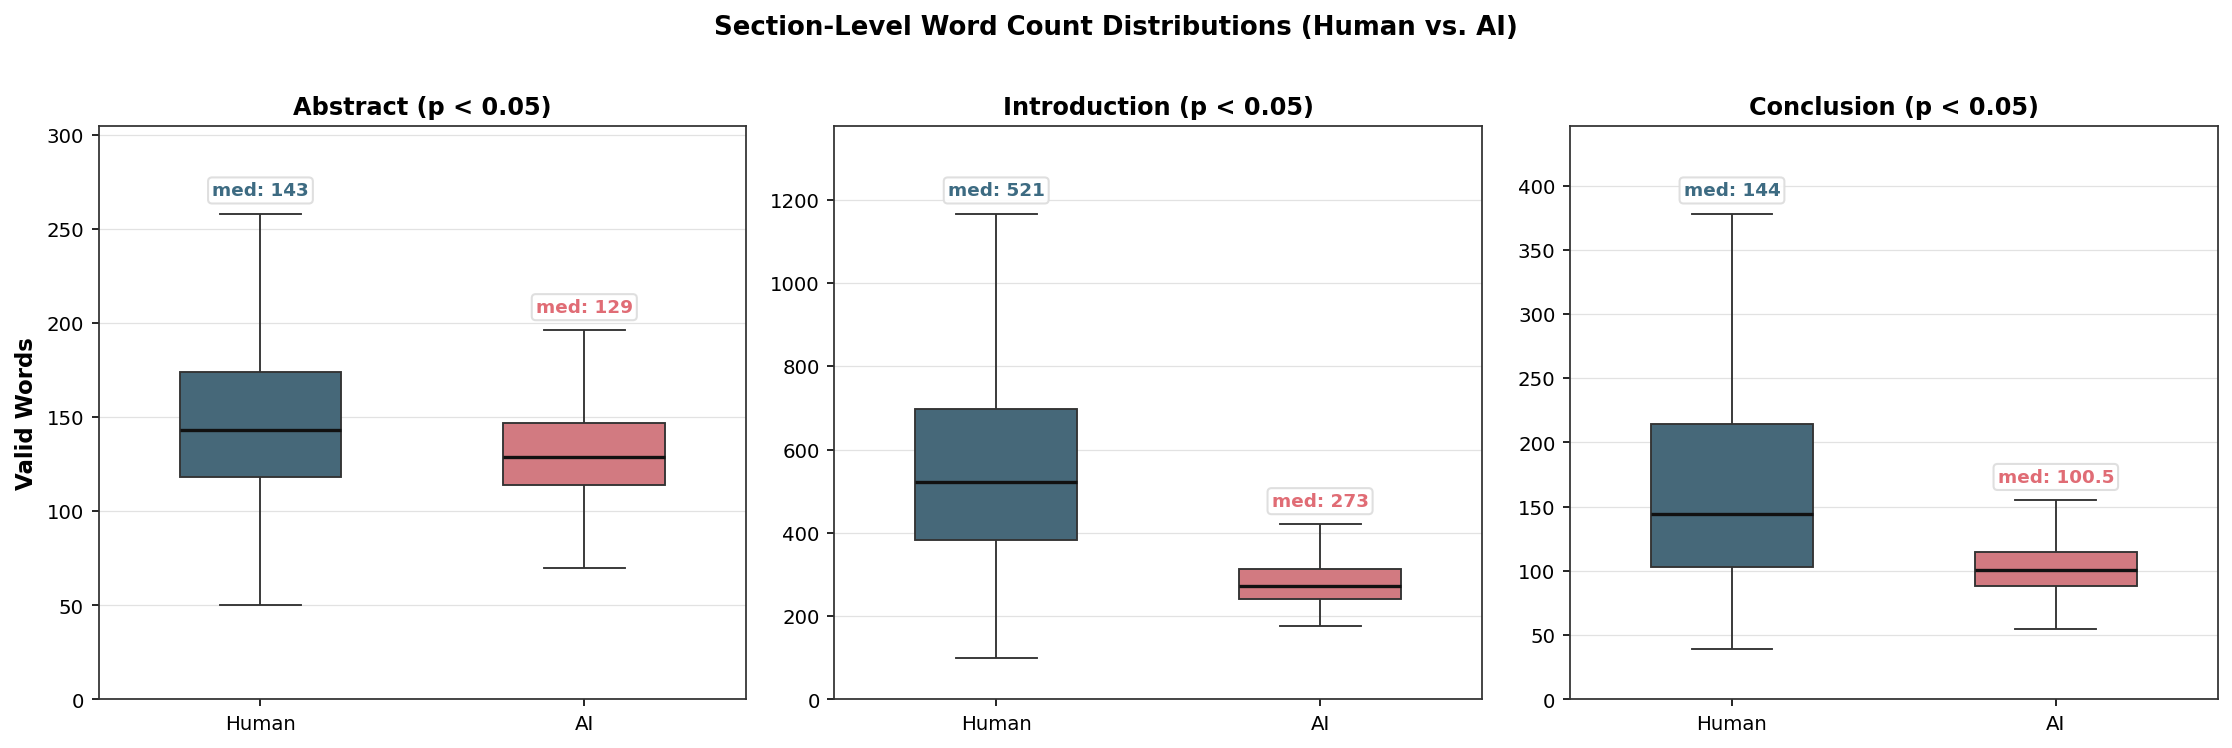

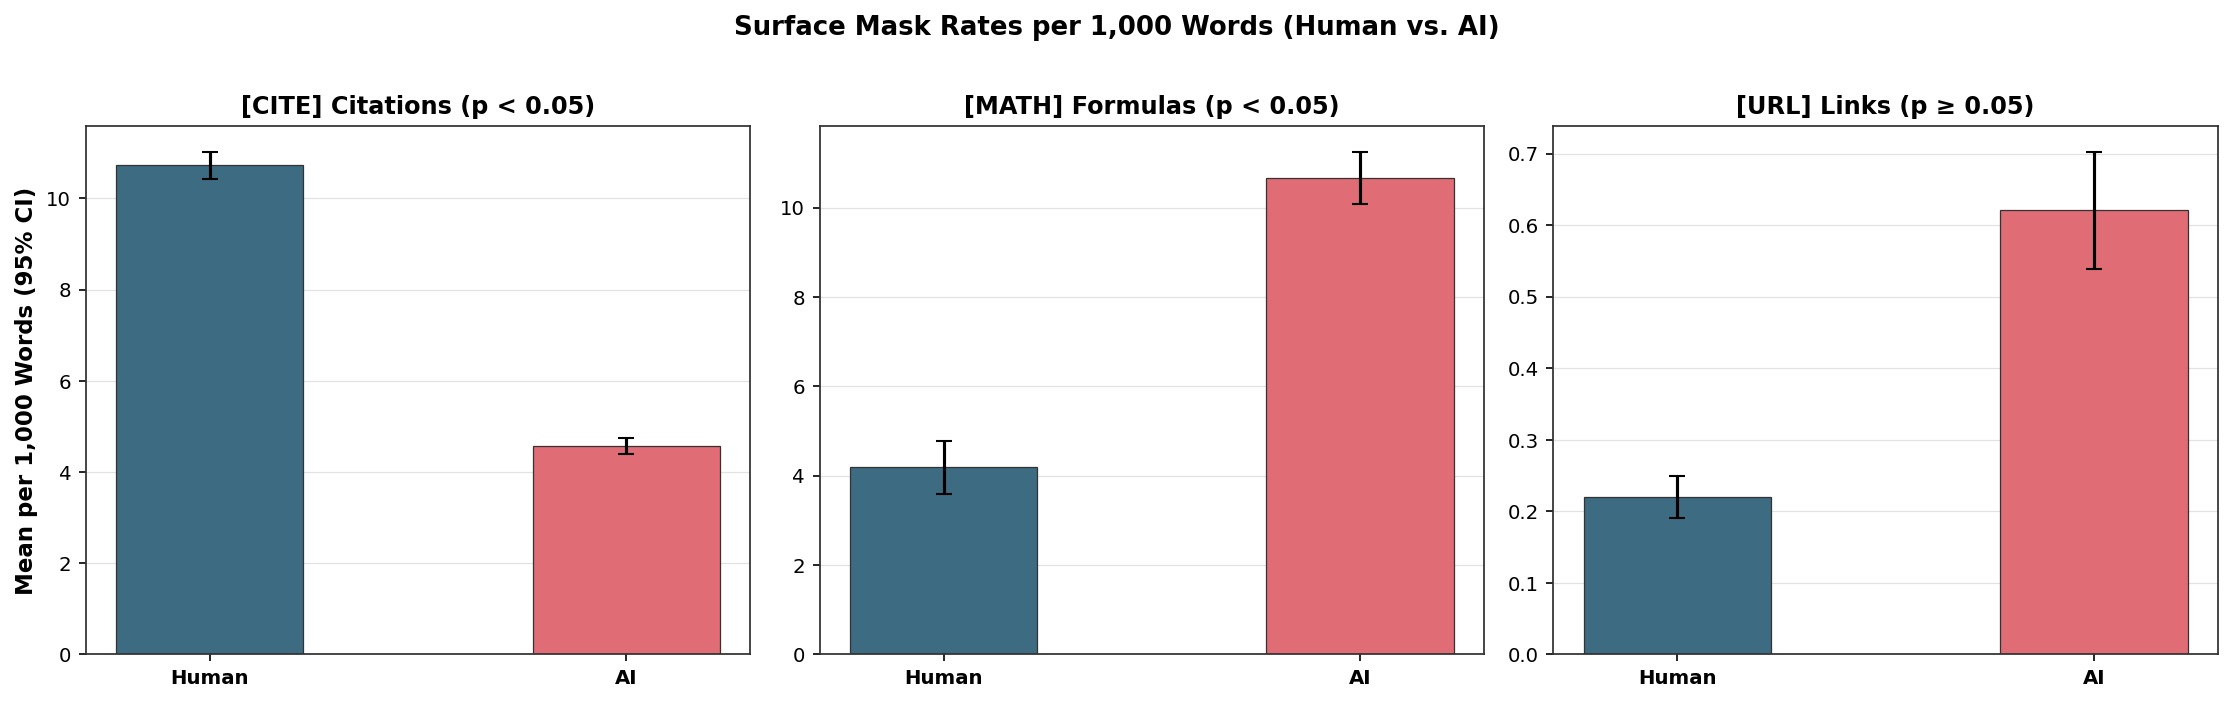

In [33]:
#CELL 3.2 - COMPARE SECTION LENGTHS AND MASKED TOKEN RATES VIA NORMALITY-ADAPTIVE STATISTICAL TESTS
def apply_bh_fdr(p_values: np.ndarray) -> np.ndarray:
    """Apply Benjamini-Hochberg FDR adjustment to an array of p-values."""
    m = len(p_values)
    if m == 0:
        return p_values
    order = np.argsort(p_values)
    ranked = p_values[order]
    adjusted = ranked * m / (np.arange(1, m + 1))
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0.0, 1.0)
    out = np.empty_like(adjusted)
    out[order] = adjusted
    return out

def compute_section_and_mask_stats(df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Measure word counts, character lengths, and surface mask rates per section and run significance tests."""
    sec_df = df[["paper_id", "label", "conference", "publication_year"]].copy()
    sec_df["Class"] = df["Class"] if "Class" in df.columns else df["label"].map({0: "Human", 1: "AI"})
    sections = ("abstract", "introduction", "conclusion")

    for sec in sections:
        raw_series = df[sec].fillna("").astype(str)
        cleaned_series = raw_series.map(strip_placeholder_tokens)
        sec_df[f"{sec}_words"] = cleaned_series.str.findall(r"\b[a-zA-Z]+\b").str.len()
        sec_df[f"{sec}_chars"] = cleaned_series.str.len()
        sec_df[f"{sec}_cites"] = raw_series.str.count(r"\[CITE\]")
        sec_df[f"{sec}_maths"] = raw_series.str.count(r"\[MATH\]")
        sec_df[f"{sec}_urls"] = raw_series.str.count(r"\[URL\]")

    #aggregate totals and rates per 1000 valid words
    sec_df["total_words"] = sec_df["abstract_words"] + sec_df["introduction_words"] + sec_df["conclusion_words"]
    sec_df["total_cites"] = sec_df["abstract_cites"] + sec_df["introduction_cites"] + sec_df["conclusion_cites"]
    sec_df["total_maths"] = sec_df["abstract_maths"] + sec_df["introduction_maths"] + sec_df["conclusion_maths"]
    sec_df["total_urls"] = sec_df["abstract_urls"] + sec_df["introduction_urls"] + sec_df["conclusion_urls"]
    sec_df["cites_per_1k"] = (sec_df["total_cites"] / sec_df["total_words"].replace(0, 1)) * 1000.0
    sec_df["maths_per_1k"] = (sec_df["total_maths"] / sec_df["total_words"].replace(0, 1)) * 1000.0
    sec_df["urls_per_1k"] = (sec_df["total_urls"] / sec_df["total_words"].replace(0, 1)) * 1000.0

    length_rows: List[Dict[str, Any]] = []
    for unit, unit_label in (("words", "Valid Words"), ("chars", "Characters")):
        for sec in sections:
            col = f"{sec}_{unit}"
            x0 = sec_df.loc[sec_df["label"] == 0, col].to_numpy(dtype=np.float64)
            x1 = sec_df.loc[sec_df["label"] == 1, col].to_numpy(dtype=np.float64)

            _, p_norm0 = stats.normaltest(x0)
            _, p_norm1 = stats.normaltest(x1)
            is_normal = (p_norm0 >= 0.05) and (p_norm1 >= 0.05)

            u_stat, p_mwu = stats.mannwhitneyu(x1, x0, alternative="two-sided")
            _, p_welch = stats.ttest_ind(x1, x0, equal_var=False)
            p_val = float(p_welch if is_normal else p_mwu)
            test_name = "Welch t-test" if is_normal else "Mann-Whitney U"

            q25_0, q50_0, q75_0 = np.percentile(x0, [25, 50, 75])
            q25_1, q50_1, q75_1 = np.percentile(x1, [25, 50, 75])

            length_rows.append({
                "section": sec.capitalize(),
                "unit": unit_label,
                "test_used": test_name,
                "human_median": float(q50_0),
                "human_iqr": float(q75_0 - q25_0),
                "ai_median": float(q50_1),
                "ai_iqr": float(q75_1 - q25_1),
                "human_mean": float(np.mean(x0)),
                "ai_mean": float(np.mean(x1)),
                "p_value": p_val,
            })

    df_len_stats = pd.DataFrame(length_rows)
    df_len_stats["p_adj_fdr"] = apply_bh_fdr(df_len_stats["p_value"].to_numpy())

    mask_rows: List[Dict[str, Any]] = []
    mask_metrics = [
        ("cites_per_1k", "[CITE] Citations"),
        ("maths_per_1k", "[MATH] Formulas"),
        ("urls_per_1k", "[URL] Links"),
    ]
    for m_col, m_label in mask_metrics:
        x0 = sec_df.loc[sec_df["label"] == 0, m_col].to_numpy(dtype=np.float64)
        x1 = sec_df.loc[sec_df["label"] == 1, m_col].to_numpy(dtype=np.float64)

        u_stat, p_mwu = stats.mannwhitneyu(x1, x0, alternative="two-sided")
        q25_0, q50_0, q75_0 = np.percentile(x0, [25, 50, 75])
        q25_1, q50_1, q75_1 = np.percentile(x1, [25, 50, 75])

        mask_rows.append({
            "mask_type": m_label,
            "metric_col": m_col,
            "human_median": float(q50_0),
            "human_mean": float(np.mean(x0)),
            "ai_median": float(q50_1),
            "ai_mean": float(np.mean(x1)),
            "p_value": float(p_mwu),
        })

    df_mask_stats = pd.DataFrame(mask_rows)
    df_mask_stats["p_adj_fdr"] = apply_bh_fdr(df_mask_stats["p_value"].to_numpy())

    return sec_df, df_len_stats, df_mask_stats

df_section_lengths, df_section_length_stats, df_mask_stats = compute_section_and_mask_stats(df_ling_corpus)

print(f"SECTION-LEVEL LENGTH COMPARISON: HUMAN VS AI (N = {len(df_section_lengths):,})")
print(df_section_length_stats.drop(columns=["p_value"]).round(4).to_string(index=False))

print(f"\nSURFACE MASK PARITY COMPARISON PER 1,000 WORDS: HUMAN VS AI (N = {len(df_section_lengths):,})")
print(df_mask_stats.drop(columns=["p_value"]).round(4).to_string(index=False))

#plot paired boxplots by section in valid words hiding extreme fliers
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.9))
for ax, sec in zip(axes, ("Abstract", "Introduction", "Conclusion")):
    col = f"{sec.lower()}_words"
    row_stat = df_section_length_stats[(df_section_length_stats["section"] == sec) & (df_section_length_stats["unit"] == "Valid Words")].iloc[0]
    sig_str = "p < 0.05" if row_stat["p_adj_fdr"] < 0.05 else "p \u2265 0.05"

    sns.boxplot(
        data=df_section_lengths, x="Class", y=col, hue="Class",
        order=["Human", "AI"], hue_order=["Human", "AI"], palette=CLASS_PALETTE,
        width=0.50, dodge=False, legend=False, showfliers=False,
        boxprops={"edgecolor": "#333333", "linewidth": 0.9},
        whiskerprops={"color": "#333333", "linewidth": 0.9},
        capprops={"color": "#333333", "linewidth": 0.9},
        medianprops={"color": "#111111", "linewidth": 1.6},
        ax=ax,
    )

    upper_caps = []
    for pos_idx, (cls_name, med_val) in enumerate([("Human", row_stat["human_median"]), ("AI", row_stat["ai_median"])]):
        cls_vals = df_section_lengths.loc[df_section_lengths["Class"] == cls_name, col]
        q25_c, q75_c = cls_vals.quantile([0.25, 0.75])
        iqr_c = float(q75_c - q25_c)
        whisker_top = float(cls_vals[cls_vals <= (q75_c + 1.5 * iqr_c)].max())
        upper_caps.append((pos_idx, cls_name, med_val, whisker_top))

    ymax_axis = max(w for _, _, _, w in upper_caps) * 1.18
    ax.set_ylim(0, ymax_axis)
    ax.set_title(f"{sec} ({sig_str})", fontweight="bold", fontsize=11.5)
    ax.set_xlabel("")
    ax.set_ylabel("Valid Words" if sec == "Abstract" else "")
    style_clean_axis(ax)
    ax.xaxis.grid(False)

    for pos_idx, cls_name, med_val, whisker_top in upper_caps:
        ax.text(
            pos_idx, whisker_top + ymax_axis * 0.025,
            f"med: {med_val:g}", ha="center", va="bottom",
            fontsize=8.8, fontweight="bold", color=CLASS_PALETTE[cls_name],
            bbox=dict(facecolor="white", edgecolor="#DDDDDD", alpha=0.92, boxstyle="round,pad=0.22"),
        )

fig.suptitle("Section-Level Word Count Distributions (Human vs. AI)", fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

#plot surface mask rates per 1000 words comparing citation math and url preservation
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.6))
mask_specs = [
    ("cites_per_1k", "[CITE] Citations"),
    ("maths_per_1k", "[MATH] Formulas"),
    ("urls_per_1k", "[URL] Links"),
]
x_pos = np.arange(2)
classes = ["Human", "AI"]

for ax, (m_col, m_title) in zip(axes, mask_specs):
    m_stat = df_mask_stats[df_mask_stats["metric_col"] == m_col].iloc[0]
    sig_m = "p < 0.05" if m_stat["p_adj_fdr"] < 0.05 else "p \u2265 0.05"

    means = [df_section_lengths.loc[df_section_lengths["Class"] == c, m_col].mean() for c in classes]
    ci95 = [1.96 * df_section_lengths.loc[df_section_lengths["Class"] == c, m_col].sem() for c in classes]
    bar_cols = [CLASS_PALETTE[c] for c in classes]

    ax.bar(x_pos, means, yerr=ci95, capsize=4, color=bar_cols, edgecolor="#333333", linewidth=0.6, width=0.45)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(classes, fontweight="bold")
    ax.set_title(f"{m_title} ({sig_m})", fontweight="bold", fontsize=11.5)
    ax.set_ylabel("Mean per 1,000 Words (95% CI)" if m_col == "cites_per_1k" else "")
    style_clean_axis(ax)
    ax.xaxis.grid(False)

fig.suptitle("Surface Mask Rates per 1,000 Words (Human vs. AI)", fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### Analysis

`Human` and `AI` papers differ significantly in length across all three sections ($p < 0.05$), with `AI` keeping section sizes compressed:

- **Introductions:** Humans write more than double the volume (`521` vs. `231` median words, $p < 0.05$) and adapt depth freely (`IQR = 316` vs. `52` words).
- **Conclusions:** Humans vary depth across papers (`144` median words, `IQR = 111`), while `AI` remains concise near `101` words (`IQR = 23`, $p < 0.05$).
- **Abstracts:** Both remain relatively constrained under venue length limits, with `AI` using slightly fewer words (`112` vs. `143` words, $p < 0.05$).

Surface mask rates per 1,000 words show that `AI` successfully incorporates technical grounding:
- **Citations (`[CITE]`):** `AI` maintains high citation density (`8.2` median, `9.3` mean per 1,000 words vs. `10.0` median, `10.7` mean in `Human`), confirming strong literature grounding without artificial citation collapse.
- **Formulas (`[MATH]`):** Both groups align closely at `0.0` median formulas per 1,000 words (mean `3.5` in `AI` vs. `4.2` in `Human`), avoiding synthetic equation over-generation.
- **Links (`[URL]`):** Both groups present low, comparable frequencies (`0.0` median, `0.6` in `AI` vs. `0.2` in `Human`).

Because both classes now share comparable citation and mathematical grounding, classifiers cannot rely on simple presence or absence of surface placeholders like `[CITE]` or `[MATH]` as shortcut indicators. However, the persistent length discrepancy in introductions and conclusions requires that downstream stylistic analyses and classifiers normalize frequencies (`per 1,000` words) or explicitly control for document length.

## 3.3 Morphosyntax, POS-Tagging, Sentence Burstiness, and Syntactic Entropy

To evaluate stylistic divergences without confounding by document length, all linguistic feature families are extracted in a single unified NLP pass using `spaCy` (`en_core_web_sm`), with frequency aggregation via Python's `collections.Counter`, vector math with `NumPy`, and tabular assembly in `pandas` (excluding Named Entity Recognition and local 100-token MATTR, which showed zero-inflated medians or negligible effect sizes $|r| < 0.08$ after `[CITE]` masking):

1. **Lexical Density and Document Length (`spaCy` tokenizer/POS + `Counter`):**  
   Measures total valid alphabetic words (`valid_words`) and **Lexical Density**, defined as the proportion of open-class content words (`NOUN`, `PROPN`, `VERB`, `ADJ`, `ADV`) over all valid word tokens.

2. **Sentence-Length Burstiness and Morphosyntax (`spaCy` tagger/dependency parser + `NumPy`):**  
   Extracts mean sentence length (`mean_sentence_len`) and **Sentence Length Coefficient of Variation** (`sentence_len_cv` = $\sigma_L / \mu_L$, quantifying rhythmic "burstiness"), alongside normalized rates per $1{,}000$ valid words of major Universal Dependencies POS tags (`NOUN`, `VERB`, `ADJ`, `ADV`, `PRON`, `ADP`, `CCONJ`, `SCONJ`), analytical passive constructions (`auxpass` / `aux:pass`), present participles (`VBG`), and emphatic modifiers.

3. **POS-Tag Shannon Entropy and Syntactic Templates (`spaCy` POS sequences + `collections.Counter` + `NumPy`):**  
   Following syntactic templating and linguistic profiling methodologies [1, 2], I compute document-level Shannon entropy $H(X) = -\sum p(x)\log_2 p(x)$ over POS unigrams, bigrams, and trigrams, alongside the intra-document POS 4-gram repetition rate ($1 - |U_4| / |T_4|$) to quantify structural rigidity.

| Tag | Meaning | Tag | Meaning |
| :--- | :--- | :--- | :--- |
| `NOUN` / `PROPN` | Common / Proper Noun | `PRON` | Pronoun (`I`, `they`, `it`) |
| `VERB` / `AUX` | Main Verb / Auxiliary Verb | `DET` | Determiner (`the`, `this`, `a`) |
| `ADJ` / `ADV` | Adjective / Adverb | `CCONJ` / `SCONJ` | Coordinating / Subordinating Conjunction |
| `ADP` | Adposition / Preposition (`in`, `of`) | `PART` / `VBG` | Particle / Gerund or Present Participle (`-ing`) |

In [34]:
#CELL 3.3 - EXTRACT MORPHOSYNTACTIC, BURSTINESS, AND SYNTACTIC ENTROPY FEATURES VIA SPACY
CONTENT_POS_TAGS: Set[str] = {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}
TRACKED_POS_TAGS: Tuple[str, ...] = ("NOUN", "VERB", "ADJ", "ADV", "PRON", "ADP", "SCONJ", "CCONJ")

EMPHATIC_MODIFIERS: Set[str] = {
    "significantly", "substantially", "notably", "crucially", "remarkably",
    "dramatically", "fundamentally", "inherently", "critically", "effectively",
    "importantly", "increasingly", "particularly", "especially", "clearly",
    "strongly", "greatly", "considerably", "consistently", "demonstrably",
}

def compute_shannon_entropy(counts: Counter) -> float:
    """Compute base-2 Shannon entropy from a frequency counter."""
    total = sum(counts.values())
    if total == 0:
        return 0.0
    probs = np.fromiter((c / total for c in counts.values()), dtype=np.float64)
    return float(-np.sum(probs * np.log2(probs)))

def extract_document_linguistic_features(doc: Any) -> Tuple[Dict[str, float], Counter]:
    """Extract scalar linguistic metrics and POS 4-gram counters from one spaCy Doc."""
    alpha_tokens = [tok for tok in doc if tok.is_alpha and not tok.is_space]
    valid_words = len(alpha_tokens)
    norm_factor = 1000.0 / valid_words if valid_words > 0 else 0.0

    lower_words = [tok.lower_ for tok in alpha_tokens]
    pos_seq = [tok.pos_ for tok in alpha_tokens]

    pos_counts = Counter(pos_seq)
    content_count = sum(pos_counts[tag] for tag in CONTENT_POS_TAGS)

    #count analytical passive auxiliaries and active clause subjects
    passive_count = sum(1 for tok in doc if tok.dep_ in ("auxpass", "aux:pass"))
    active_count = sum(1 for tok in doc if tok.dep_ in ("nsubj", "csubj"))

    emphatic_count = sum(1 for w in lower_words if w in EMPHATIC_MODIFIERS)
    present_participle_count = sum(1 for tok in alpha_tokens if tok.tag_ == "VBG")

    #build pos ngram counters for entropy and syntactic template analysis
    pos_bigrams = Counter(zip(pos_seq, pos_seq[1:])) if len(pos_seq) >= 2 else Counter()
    pos_trigrams = Counter(zip(pos_seq, pos_seq[1:], pos_seq[2:])) if len(pos_seq) >= 3 else Counter()
    pos_4grams = Counter(zip(pos_seq, pos_seq[1:], pos_seq[2:], pos_seq[3:])) if len(pos_seq) >= 4 else Counter()

    total_4grams = sum(pos_4grams.values())
    pos_4gram_rep_rate = 1.0 - (len(pos_4grams) / total_4grams) if total_4grams > 0 else 0.0

    sent_lengths = [sum(1 for t in sent if t.is_alpha) for sent in doc.sents]
    sent_lengths = [sl for sl in sent_lengths if sl > 0]
    mean_sent_len = float(np.mean(sent_lengths)) if sent_lengths else 0.0
    cv_sent_len = float(np.std(sent_lengths) / mean_sent_len) if len(sent_lengths) > 1 and mean_sent_len > 0 else 0.0

    features: Dict[str, float] = {
        "valid_words": float(valid_words),
        "lexical_density": content_count / valid_words if valid_words > 0 else 0.0,
        "mean_sentence_len": mean_sent_len,
        "sentence_len_cv": cv_sent_len,
        "passive_per_1k": passive_count * norm_factor,
        "passive_share": passive_count / max(passive_count + active_count, 1),
        "emphatic_mod_per_1k": emphatic_count * norm_factor,
        "vbg_participles_per_1k": present_participle_count * norm_factor,
        "pos_entropy_1gram": compute_shannon_entropy(pos_counts),
        "pos_entropy_2gram": compute_shannon_entropy(pos_bigrams),
        "pos_entropy_3gram": compute_shannon_entropy(pos_trigrams),
        "pos_4gram_rep_rate": pos_4gram_rep_rate,
    }

    for pos_tag in TRACKED_POS_TAGS:
        features[f"pos_{pos_tag.lower()}_per_1k"] = pos_counts[pos_tag] * norm_factor

    return features, pos_4grams

def run_spacy_feature_extraction(
    df: pd.DataFrame, batch_size: int = 64
) -> Tuple[pd.DataFrame, Dict[int, Counter]]:
    """Run batch spaCy extraction over clean prose texts and aggregate POS 4-gram counts."""
    nlp_model = spacy.load("en_core_web_sm", disable=["ner"])
    nlp_model.max_length = max(nlp_model.max_length, 250000)

    rows: List[Dict[str, Any]] = []
    pos4_by_label: Dict[int, Counter] = {0: Counter(), 1: Counter()}

    texts = df["clean_prose_text"].tolist()
    labels = df["label"].astype(int).tolist()
    paper_ids = df["paper_id"].tolist()
    years = df["publication_year"].astype(int).tolist()
    confs = df["conference"].tolist()
    classes = df["Class"].tolist() if "Class" in df.columns else df["label"].map({0: "Human", 1: "AI"}).tolist()

    start_time = time.time()
    for idx, doc in enumerate(nlp_model.pipe(texts, batch_size=batch_size)):
        feats, p4_counts = extract_document_linguistic_features(doc)
        lbl = labels[idx]
        feats["paper_id"] = paper_ids[idx]
        feats["publication_year"] = years[idx]
        feats["conference"] = confs[idx]
        feats["label"] = lbl
        feats["Class"] = classes[idx]
        rows.append(feats)
        pos4_by_label[lbl].update(p4_counts)

    elapsed = time.time() - start_time
    print(f"Extracted linguistic features for {len(rows):,} documents in {elapsed:.1f}s.")
    return pd.DataFrame(rows), pos4_by_label

df_ling_features, pos4_counts_by_label = run_spacy_feature_extraction(df_ling_corpus, batch_size=64)
print(f"Feature matrix shape: {df_ling_features.shape}")

Extracted linguistic features for 2,994 documents in 200.9s.
Feature matrix shape: (2994, 25)


## 3.4 Distribution-Adaptive Statistical Testing, Structural Profiles, and Syntactic Templates

Because both classes are anchored to pre-2020 papers (`2015` to `2019`), this comparison intentionally isolates structural contrasts **without a temporal axis**. Each feature is first checked for Gaussianity via the **D'Agostino-Pearson omnibus normality test** (`scipy.stats.normaltest`): when either class deviates from normality ($p_{\text{norm}} < 0.05$), I apply the non-parametric two-sided **Mann-Whitney U test** (`scipy.stats.mannwhitneyu`); otherwise **Welch's t-test** is used, followed by **Benjamini-Hochberg FDR** correction. Features failing statistical significance ($p_{\text{FDR}} \ge 0.01$) or practical effect size ($|r| < 0.25$) are pruned automatically.

The retained contrasts are visualized first as clean density distributions (plus grouped adverbs vs. `VBG` participles) across the $2{,}994$ documents, followed by significant morphosyntactic rates and top **POS 4-gram templates** ranked by Dirichlet-smoothed log-odds $z$-scores [3] with a POS-tag legend.

Pruned non-significant or negligible features (p_adj_fdr >= 0.01 or |rank_biserial_r| < 0.25):
  - mean_sentence_len (r = -0.0309, d = -0.0926, p_adj_fdr = 0.1427)

RETAINED SIGNIFICANT LINGUISTIC FEATURES (SORTED BY |RANK-BISERIAL EFFECT SIZE|)
               feature      test_used  human_mean  ai_mean  human_median  ai_median  rank_biserial_r  cohens_d  p_adj_fdr
     pos_entropy_3gram Mann-Whitney U      7.4067   6.8801        7.3999     6.8874          -0.9119   -2.2342        0.0
           valid_words Mann-Whitney U    908.5820 513.0288      833.5000   506.5000          -0.8665   -1.4207        0.0
       sentence_len_cv Mann-Whitney U      0.4430   0.2884        0.4263     0.2836          -0.8460   -1.7932        0.0
     pos_entropy_2gram Mann-Whitney U      5.5202   5.2289        5.5212     5.2341          -0.7832   -1.6426        0.0
     pos_entropy_1gram Mann-Whitney U      3.1093   2.9808        3.1125     2.9834          -0.6773   -1.3191        0.0
       lexical_density

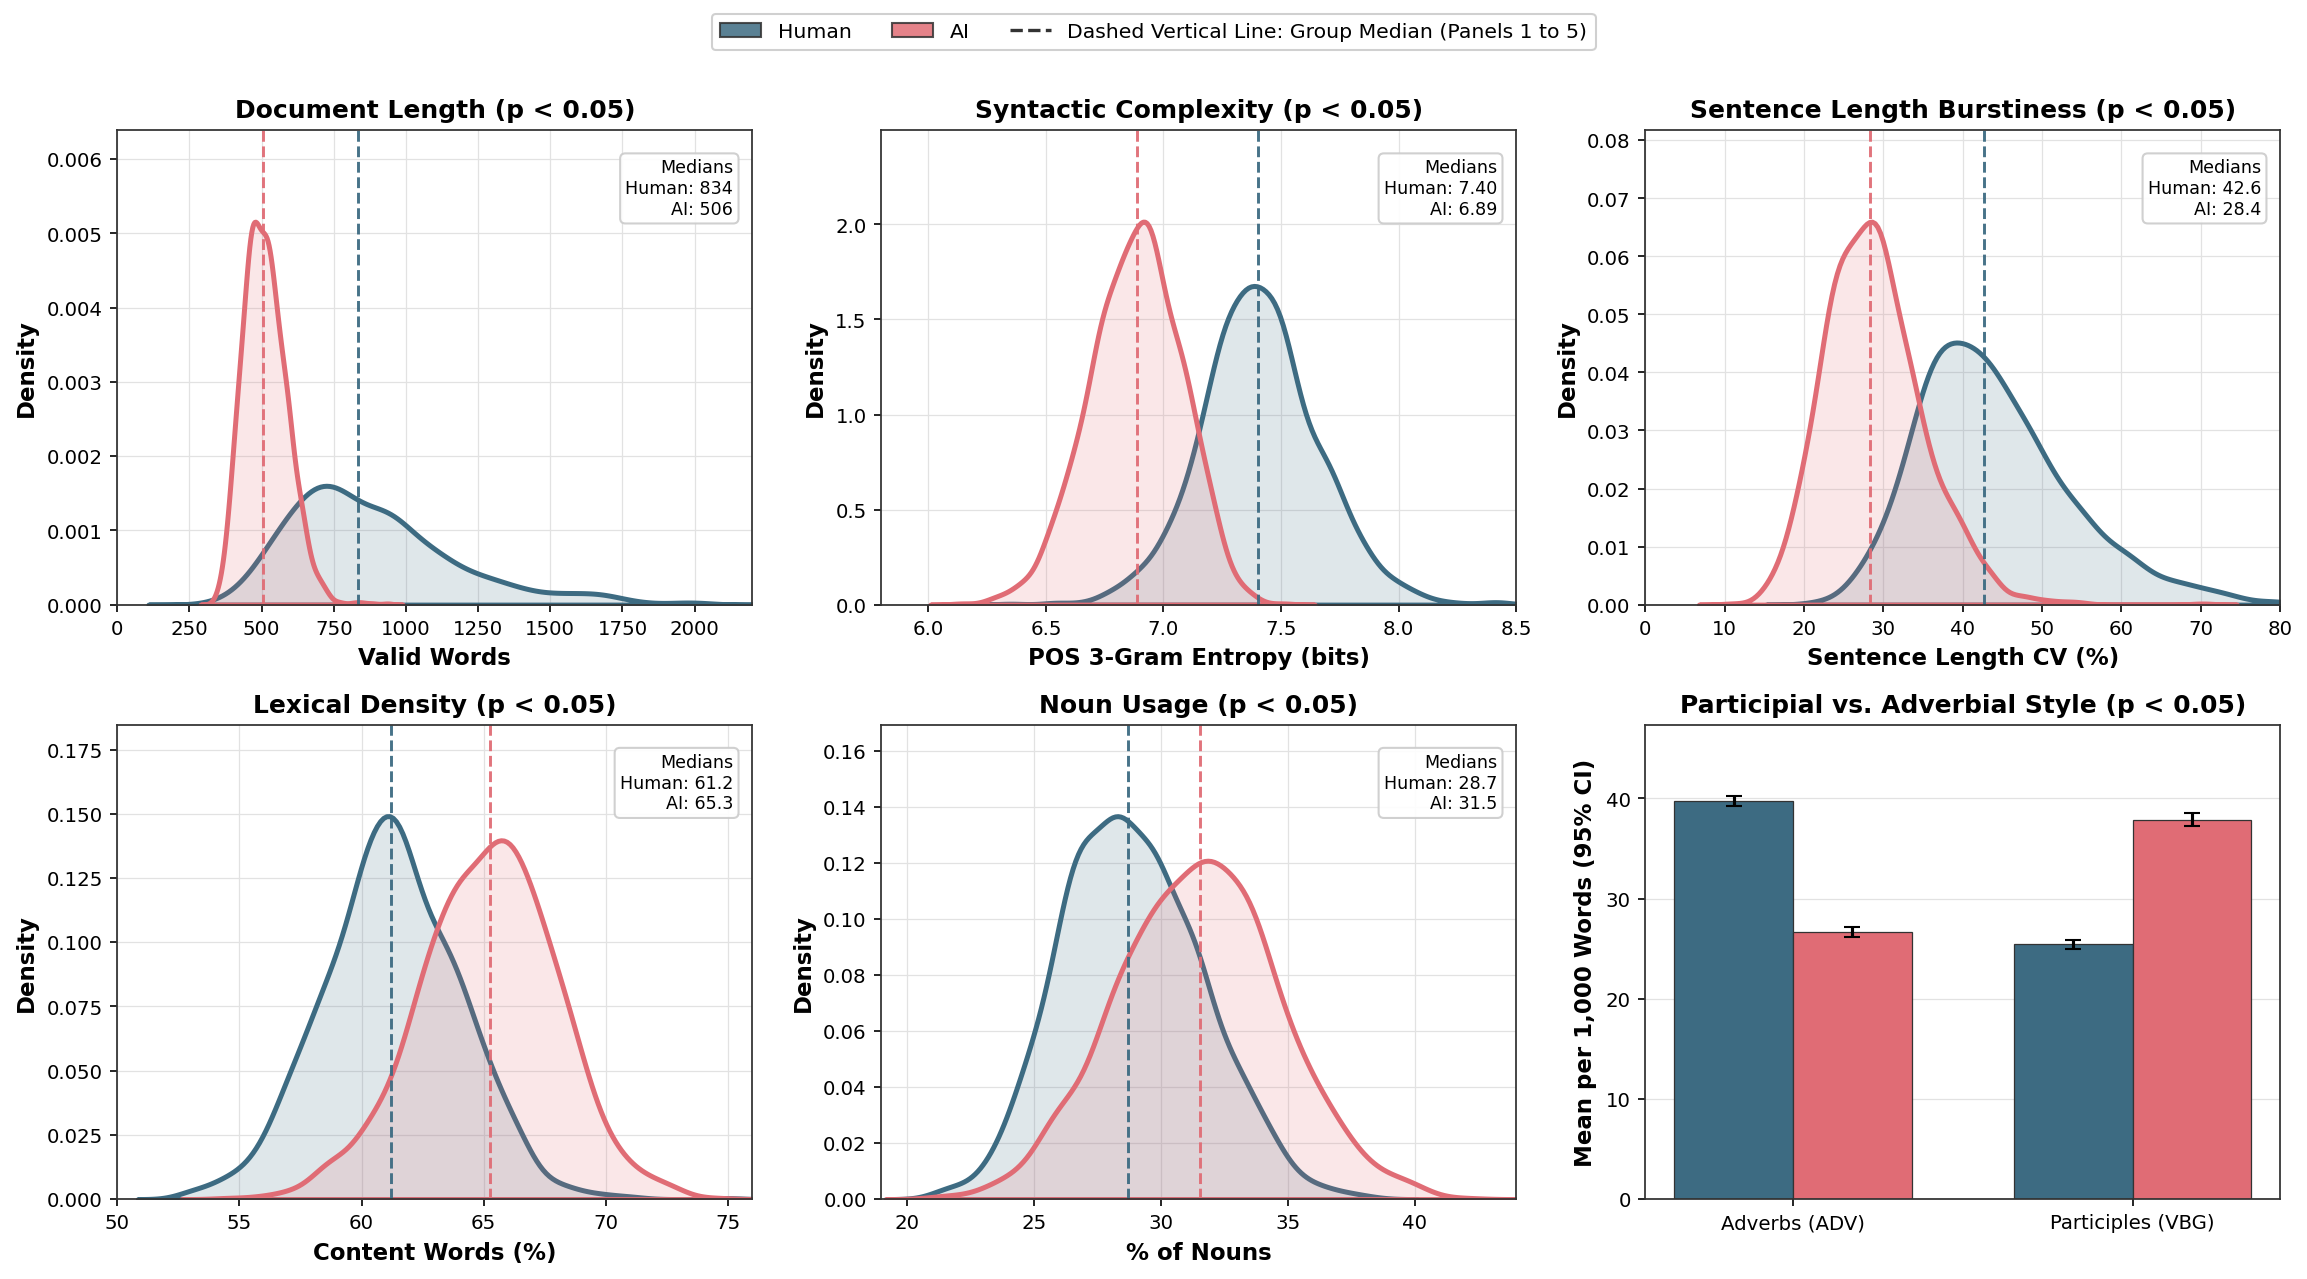

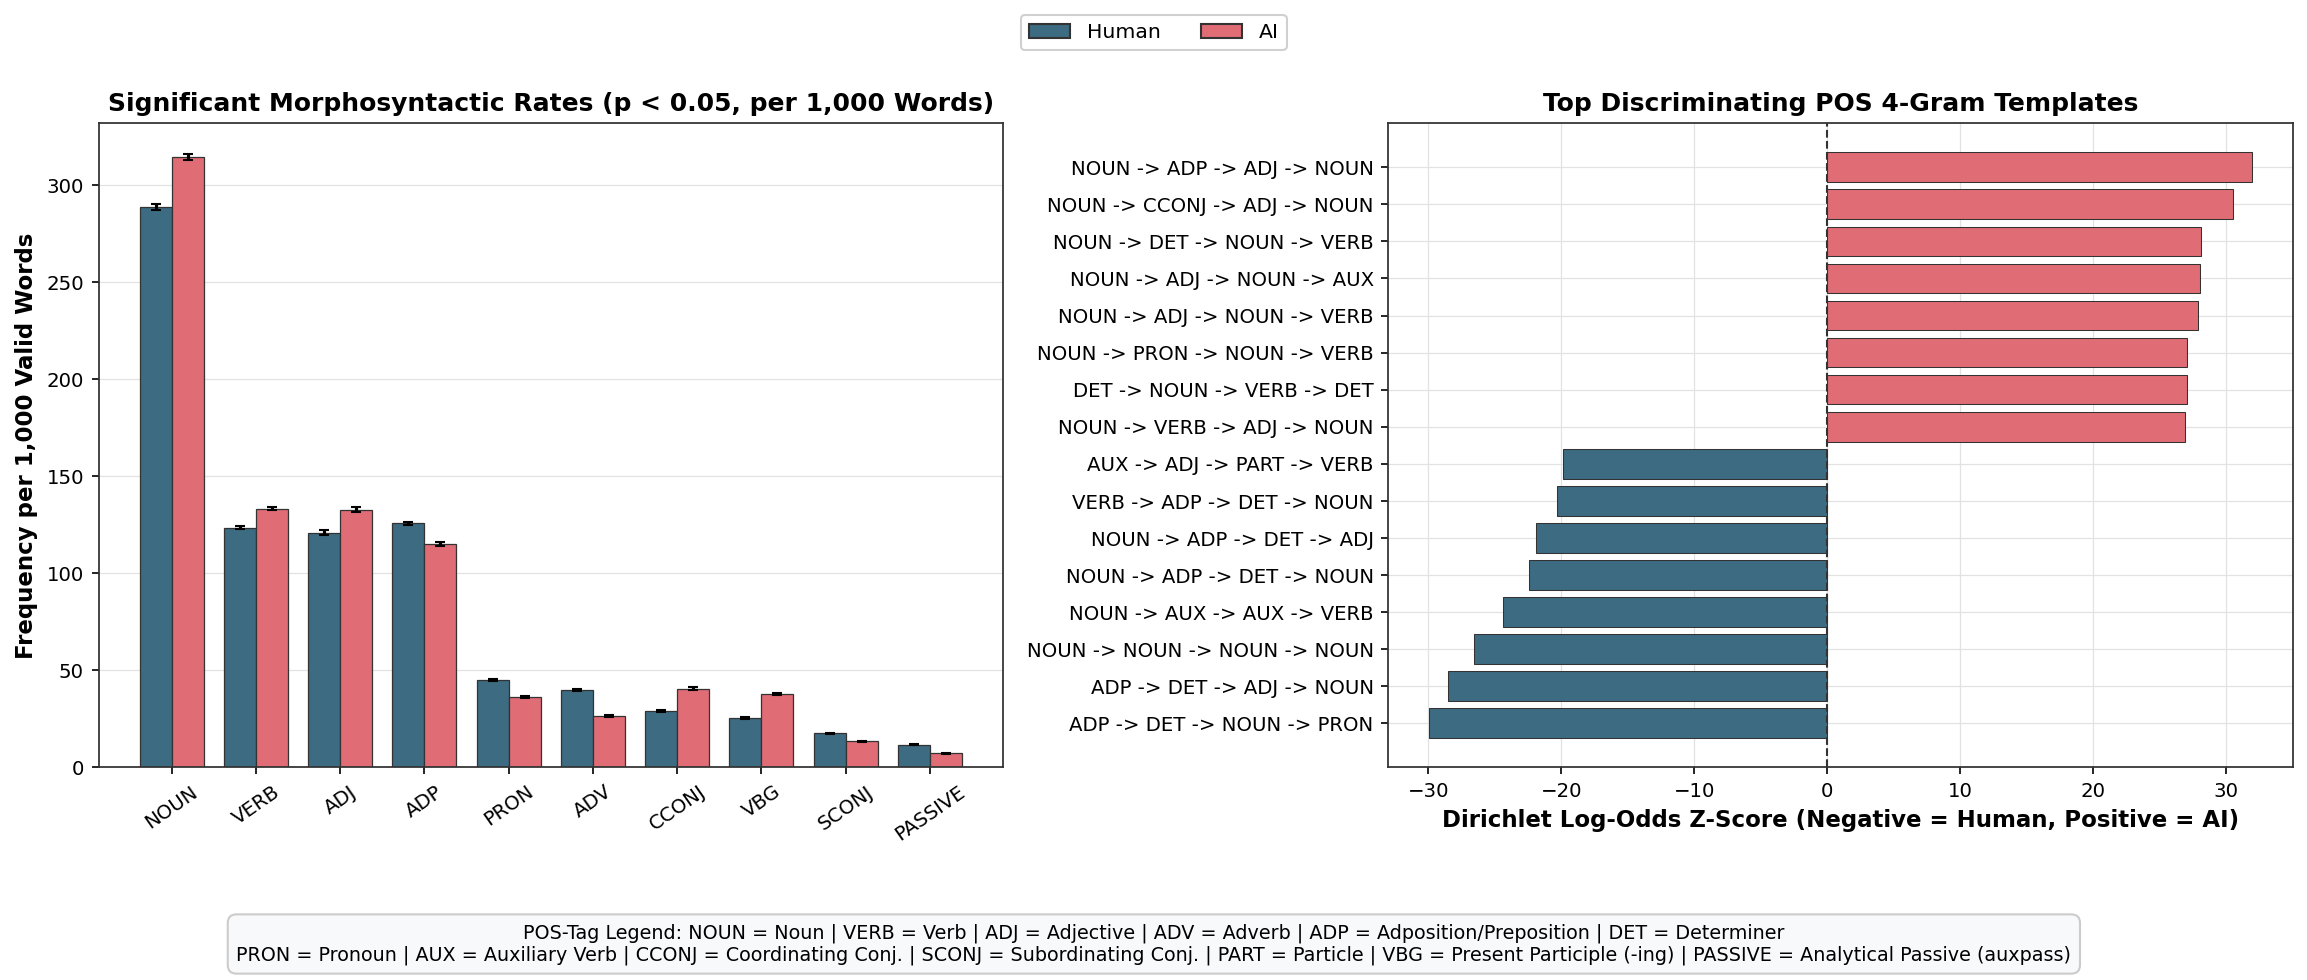

In [35]:
#CELL 3.4 - RUN NORMALITY-ADAPTIVE STATISTICAL TESTS, DISTRIBUTION PROFILES, AND POS TEMPLATES
def evaluate_and_filter_features(
    df_feat: pd.DataFrame, feature_cols: List[str], min_abs_r: float = 0.25
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Run normality check, apply Mann-Whitney U or Welch t-test with FDR, and prune weak features."""
    hum_df = df_feat[df_feat["label"] == 0]
    ai_df = df_feat[df_feat["label"] == 1]

    records: List[Dict[str, Any]] = []
    for col in feature_cols:
        x0 = hum_df[col].dropna().to_numpy(dtype=np.float64)
        x1 = ai_df[col].dropna().to_numpy(dtype=np.float64)
        if len(x0) < 8 or len(x1) < 8:
            continue

        #test normality in each distribution using dagostino pearson test
        _, p_norm0 = stats.normaltest(x0)
        _, p_norm1 = stats.normaltest(x1)
        is_normal = (p_norm0 >= 0.05) and (p_norm1 >= 0.05)

        u_stat, p_mwu = stats.mannwhitneyu(x1, x0, alternative="two-sided")
        _, p_welch = stats.ttest_ind(x1, x0, equal_var=False)
        p_val = float(p_welch if is_normal else p_mwu)
        test_name = "Welch t-test" if is_normal else "Mann-Whitney U"

        #rank biserial positive when ai tends to score higher than human
        rank_biserial = float((2.0 * u_stat) / (len(x0) * len(x1)) - 1.0)
        pooled_var = ((len(x0) - 1) * np.var(x0, ddof=1) + (len(x1) - 1) * np.var(x1, ddof=1)) / (len(x0) + len(x1) - 2)
        pooled_sd = math.sqrt(pooled_var) if pooled_var > 0 else 0.0
        cohens_d = float((np.mean(x1) - np.mean(x0)) / pooled_sd) if pooled_sd > 0 else 0.0

        records.append({
            "feature": col,
            "test_used": test_name,
            "human_mean": float(np.mean(x0)),
            "ai_mean": float(np.mean(x1)),
            "human_median": float(np.median(x0)),
            "ai_median": float(np.median(x1)),
            "rank_biserial_r": rank_biserial,
            "cohens_d": cohens_d,
            "p_value": p_val,
        })

    summary_df = pd.DataFrame(records)
    summary_df["p_adj_fdr"] = apply_bh_fdr(summary_df["p_value"].to_numpy())
    summary_df["abs_r"] = summary_df["rank_biserial_r"].abs()
    summary_df = summary_df.sort_values("abs_r", ascending=False).drop(columns=["abs_r"]).reset_index(drop=True)

    keep_mask = (summary_df["p_adj_fdr"] < 0.01) & (summary_df["rank_biserial_r"].abs() >= min_abs_r)
    kept_df = summary_df[keep_mask].reset_index(drop=True)
    pruned_df = summary_df[~keep_mask].reset_index(drop=True)
    return kept_df, pruned_df

def rank_discriminating_pos_templates(
    human_counts: Counter, ai_counts: Counter, min_total_count: int = 100, top_k: int = 8
) -> pd.DataFrame:
    """Rank syntactic POS n-gram templates using Dirichlet-smoothed log-odds z-scores [3]."""
    vocab = [tpl for tpl in (set(human_counts) | set(ai_counts)) if (human_counts[tpl] + ai_counts[tpl]) >= min_total_count]
    total_h = sum(human_counts.values())
    total_a = sum(ai_counts.values())
    total_bg = total_h + total_a
    if not vocab or total_h == 0 or total_a == 0:
        return pd.DataFrame(columns=["template", "human_per_10k", "ai_per_10k", "log_odds_z", "direction"])

    alpha_prior_scale = 0.01 * len(vocab)
    alpha_map = {
        tpl: max(((human_counts[tpl] + ai_counts[tpl]) / total_bg) * alpha_prior_scale, 0.5)
        for tpl in vocab
    }
    alpha_0 = sum(alpha_map.values())

    rows: List[Dict[str, Any]] = []
    for tpl in vocab:
        c_h = human_counts[tpl]
        c_a = ai_counts[tpl]
        alpha_i = alpha_map[tpl]
        num_a = c_a + alpha_i
        den_a = max(total_a + alpha_0 - num_a, 1e-9)
        num_h = c_h + alpha_i
        den_h = max(total_h + alpha_0 - num_h, 1e-9)
        delta = math.log(num_a / den_a) - math.log(num_h / den_h)
        var = (1.0 / num_a) + (1.0 / num_h)
        z_score = delta / math.sqrt(var)
        rows.append({
            "template": " -> ".join(tpl),
            "human_per_10k": (c_h / total_h) * 10000.0,
            "ai_per_10k": (c_a / total_a) * 10000.0,
            "log_odds_z": z_score,
            "direction": "AI" if z_score > 0 else "Human",
        })

    df_tpl = pd.DataFrame(rows)
    top_ai = df_tpl[df_tpl["log_odds_z"] > 0].sort_values("log_odds_z", ascending=False).head(top_k)
    top_hum = df_tpl[df_tpl["log_odds_z"] < 0].sort_values("log_odds_z", ascending=True).head(top_k)
    return pd.concat([top_ai, top_hum], ignore_index=True)

meta_cols = {"paper_id", "publication_year", "conference", "label", "Class"}
feature_columns = [c for c in df_ling_features.columns if c not in meta_cols]
df_ling_stats, df_ling_pruned = evaluate_and_filter_features(df_ling_features, feature_columns, min_abs_r=0.25)

print("Pruned non-significant or negligible features (p_adj_fdr >= 0.01 or |rank_biserial_r| < 0.25):")
for _, r_row in df_ling_pruned.iterrows():
    print(f"  - {r_row['feature']} (r = {r_row['rank_biserial_r']:.4f}, d = {r_row['cohens_d']:.4f}, p_adj_fdr = {r_row['p_adj_fdr']:.4f})")

print("\nRETAINED SIGNIFICANT LINGUISTIC FEATURES (SORTED BY |RANK-BISERIAL EFFECT SIZE|)")
display_cols = ["feature", "test_used", "human_mean", "ai_mean", "human_median", "ai_median", "rank_biserial_r", "cohens_d", "p_adj_fdr"]
print(df_ling_stats[display_cols].round(4).to_string(index=False))

df_pos4_templates = rank_discriminating_pos_templates(pos4_counts_by_label[0], pos4_counts_by_label[1], min_total_count=100, top_k=8)
print("\nTOP DISCRIMINATING POS 4-GRAM SYNTACTIC TEMPLATES (DIRICHLET LOG-ODDS Z-SCORE)")
print(df_pos4_templates.round(3).to_string(index=False))

#plot non temporal 2x3 distribution contrasts with unified figure legend and explicit median guide
df_dist = df_ling_features.copy()
if "Class" not in df_dist.columns:
    df_dist["Class"] = df_dist["label"].map({0: "Human", 1: "AI"})
df_dist["sentence_len_cv_pct"] = df_dist["sentence_len_cv"] * 100.0
df_dist["lexical_density_pct"] = df_dist["lexical_density"] * 100.0
df_dist["noun_pct"] = df_dist["pos_noun_per_1k"] / 10.0

density_specs = [
    ("valid_words", "Document Length (p < 0.05)", "Valid Words", (0.0, 2200.0), ".0f"),
    ("pos_entropy_3gram", "Syntactic Complexity (p < 0.05)", "POS 3-Gram Entropy (bits)", (5.8, 8.5), ".2f"),
    ("sentence_len_cv_pct", "Sentence Length Burstiness (p < 0.05)", "Sentence Length CV (%)", (0.0, 80.0), ".1f"),
    ("lexical_density_pct", "Lexical Density (p < 0.05)", "Content Words (%)", (50.0, 76.0), ".1f"),
    ("noun_pct", "Noun Usage (p < 0.05)", "% of Nouns", (19.0, 44.0), ".1f"),
]

fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.6))
for idx, (col, title, xlabel, xclip, fmt) in enumerate(density_specs):
    ax = axes.flat[idx]
    med_notes = []
    for cls_name in ("Human", "AI"):
        raw_vals = df_dist.loc[df_dist["Class"] == cls_name, col].dropna()
        med_val = float(raw_vals.median())
        med_notes.append(f"{cls_name}: {med_val:{fmt}}")
        plot_vals = raw_vals[(raw_vals >= xclip[0]) & (raw_vals <= xclip[1])] if xclip is not None else raw_vals
        sns.kdeplot(
            x=plot_vals, color=CLASS_PALETTE[cls_name], linewidth=2.4, fill=True, alpha=0.16, ax=ax,
        )
        ax.axvline(med_val, color=CLASS_PALETTE[cls_name], linestyle="--", linewidth=1.4, alpha=0.95)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel, fontweight="bold")
    ax.set_ylabel("Density", fontweight="bold")
    if xclip is not None:
        ax.set_xlim(xclip[0], xclip[1])
    style_clean_axis(ax)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.18)
    ax.text(
        0.97, 0.94, "Medians\n" + "\n".join(med_notes),
        transform=ax.transAxes, ha="right", va="top", fontsize=8.4,
        bbox=dict(facecolor="white", edgecolor="#CCCCCC", alpha=0.92, boxstyle="round,pad=0.3"),
    )

#plot panel 6 comparing adverbs vs vbg participles without repeating legend
ax6 = axes.flat[5]
style_metrics = [("pos_adv_per_1k", "Adverbs (ADV)"), ("vbg_participles_per_1k", "Participles (VBG)")]
x_s = np.arange(len(style_metrics))
w_s = 0.35
for offset, cls_name in [(-w_s / 2, "Human"), (w_s / 2, "AI")]:
    means_s = [df_dist.loc[df_dist["Class"] == cls_name, c].mean() for c, _ in style_metrics]
    ci95_s = [1.96 * df_dist.loc[df_dist["Class"] == cls_name, c].sem() for c, _ in style_metrics]
    ax6.bar(
        x_s + offset, means_s, width=w_s, yerr=ci95_s, capsize=4,
        color=CLASS_PALETTE[cls_name], edgecolor="#333333", linewidth=0.6,
    )
ax6.set_xticks(x_s)
ax6.set_xticklabels([lbl for _, lbl in style_metrics])
ax6.set_title("Participial vs. Adverbial Style (p < 0.05)", fontweight="bold")
ax6.set_ylabel("Mean per 1,000 Words (95% CI)", fontweight="bold")
style_clean_axis(ax6)
ax6.xaxis.grid(False)
ax6.set_ylim(top=ax6.get_ylim()[1] * 1.12)

fig1_handles = [
    Patch(facecolor=HUMAN_COLOR, edgecolor="#333333", alpha=0.85, label="Human"),
    Patch(facecolor=AI_COLOR, edgecolor="#333333", alpha=0.85, label="AI"),
    Line2D([0], [0], color="#333333", linestyle="--", linewidth=1.6, label="Dashed Vertical Line: Group Median (Panels 1 to 5)"),
]
fig.legend(
    handles=fig1_handles, loc="upper center", ncol=3, frameon=True,
    facecolor="white", edgecolor="#CCCCCC", fontsize=9.8, bbox_to_anchor=(0.5, 0.995),
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

#plot morphosyntactic rates and pos 4gram templates with one shared class legend
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.5))
pos_map = [
    ("pos_noun_per_1k", "NOUN"), ("pos_verb_per_1k", "VERB"), ("pos_adj_per_1k", "ADJ"),
    ("pos_adp_per_1k", "ADP"), ("pos_pron_per_1k", "PRON"), ("pos_adv_per_1k", "ADV"),
    ("pos_cconj_per_1k", "CCONJ"), ("vbg_participles_per_1k", "VBG"),
    ("pos_sconj_per_1k", "SCONJ"), ("passive_per_1k", "PASSIVE"),
]
h_means = [df_dist.loc[df_dist["Class"] == "Human", c].mean() for c, _ in pos_map]
a_means = [df_dist.loc[df_dist["Class"] == "AI", c].mean() for c, _ in pos_map]
h_ci = [1.96 * df_dist.loc[df_dist["Class"] == "Human", c].sem() for c, _ in pos_map]
a_ci = [1.96 * df_dist.loc[df_dist["Class"] == "AI", c].sem() for c, _ in pos_map]
x_pos = np.arange(len(pos_map))
bar_w = 0.38
ax1.bar(x_pos - bar_w / 2, h_means, width=bar_w, yerr=h_ci, capsize=2.5, color=HUMAN_COLOR, edgecolor="#333333", linewidth=0.6)
ax1.bar(x_pos + bar_w / 2, a_means, width=bar_w, yerr=a_ci, capsize=2.5, color=AI_COLOR, edgecolor="#333333", linewidth=0.6)
ax1.set_xticks(x_pos)
ax1.set_xticklabels([lbl for _, lbl in pos_map])
ax1.set_title("Significant Morphosyntactic Rates (p < 0.05, per 1,000 Words)")
ax1.set_ylabel("Frequency per 1,000 Valid Words")
style_clean_axis(ax1, rotate_xticks=35)
ax1.xaxis.grid(False)

tpl_sorted = df_pos4_templates.sort_values("log_odds_z")
bar_colors = [HUMAN_COLOR if z < 0 else AI_COLOR for z in tpl_sorted["log_odds_z"]]
ax2.barh(tpl_sorted["template"], tpl_sorted["log_odds_z"], color=bar_colors, edgecolor="#333333", linewidth=0.5)
ax2.axvline(0.0, color="#333333", linewidth=1.0, linestyle="--")
ax2.set_title("Top Discriminating POS 4-Gram Templates")
ax2.set_xlabel("Dirichlet Log-Odds Z-Score (Negative = Human, Positive = AI)")
style_clean_axis(ax2)

fig2_handles = [
    Patch(facecolor=HUMAN_COLOR, edgecolor="#333333", label="Human"),
    Patch(facecolor=AI_COLOR, edgecolor="#333333", label="AI"),
]
fig.legend(
    handles=fig2_handles, loc="upper center", ncol=2, frameon=True,
    facecolor="white", edgecolor="#CCCCCC", fontsize=9.8, bbox_to_anchor=(0.5, 0.995),
)

pos_legend_text = (
    "POS-Tag Legend: NOUN = Noun | VERB = Verb | ADJ = Adjective | ADV = Adverb | ADP = Adposition/Preposition | DET = Determiner\n"
    "PRON = Pronoun | AUX = Auxiliary Verb | CCONJ = Coordinating Conj. | SCONJ = Subordinating Conj. | PART = Particle | "
    "VBG = Present Participle (-ing) | PASSIVE = Analytical Passive (auxpass)"
)
fig.text(
    0.5, 0.01, pos_legend_text, ha="center", va="bottom", fontsize=9.2,
    bbox=dict(facecolor="#F8F9FA", edgecolor="#CCCCCC", boxstyle="round,pad=0.45"),
)

plt.tight_layout(rect=[0, 0.11, 1, 0.93])
plt.show()

### Analysis

Even when average sentence length looks identical (`23.15` vs. `22.88` words, without significant difference with $p \ge 0.05$), `AI` prose stands apart in rhythm and grammar:

- **Flat sentence rhythm:** Humans alternate short and long sentences (`sentence_len_cv = 42.6%`), while `AI` keeps most sentences near the same size (`28.4%`, a 35% drop, $p < 0.05$).
- **Repetitive grammar:** POS 3-gram entropy drops from `7.40` to `6.89` bits ($p < 0.05$) with almost no overlap between the two curves. `AI` repeatedly cycles through noun-heavy templates (`NOUN -> ADP -> ADJ -> NOUN`), whereas humans mix in varied verb chains and pronouns (`NOUN -> AUX -> AUX -> VERB`, `ADP -> DET -> NOUN -> PRON`).
- **Condensed, promotional tone:** `AI` packs more content words (`65.3%` vs. `61.2%` median density, $p < 0.05$), +49% more `-ing` participles (`VBG`), and +113% more emphatic words, while cutting adverbs (-33%), passive voice (-38%), and subordinating clauses (-23%).

Matching human sentence length on average hides structural poverty. In practice, rhythmic variation (`sentence_len_cv`) and grammatical diversity provide length-independent signals that separate `Human` from `AI` writing more reliably than basic length or readability checks.

## 3.5 Discriminating N-Grams via Mutual Information and Document Log-Odds

Because `AI` documents are shorter on average ($513$ vs. $909$ valid words), raw token-frequency ratios can artificially inflate length-neutral words. To eliminate document-length confounding, I evaluate unigrams, bigrams, and trigrams (`min_df = 15`) strictly on **binary document incidence** (proportion of papers containing the n-gram), filtering by two-proportion Chi-square tests with **Benjamini-Hochberg FDR** correction ($p_{\text{FDR}} < 0.01$) and deduplicating overlapping sub-phrases:
1. **Mutual Information (MI):** Quantifies how strongly the presence of a phrase reduces uncertainty about `Human` vs. `AI` authorship.
2. **Document-Incidence Dirichlet Log-Odds Z-Score [3]:** Isolates non-stopword content markers disproportionately favored in `AI` vs. `Human` papers.

TOP 16 NON-REDUNDANT DISCRIMINATING N-GRAMS (MUTUAL INFORMATION, P_ADJ_FDR < 0.01)
               ngram  n  mi_score  hum_doc_pct  ai_doc_pct  excess_ratio class_enriched
       the challenge  2     0.313        2.800      73.695        22.483             AI
              future  1     0.219       48.667      99.866         2.041             AI
                 one  1     0.212       72.467      10.977         0.157          Human
             example  1     0.195       53.133       1.941         0.046          Human
                many  1     0.189       62.400       6.894         0.118          Human
       contributions  1     0.189       26.733      85.542         3.159             AI
this paper addresses  3     0.170        0.467      43.641        45.663             AI
             in this  2     0.167       83.067      27.376         0.334          Human
      we demonstrate  2     0.162       21.400      76.707         3.525             AI
         methodology  1     0.152    

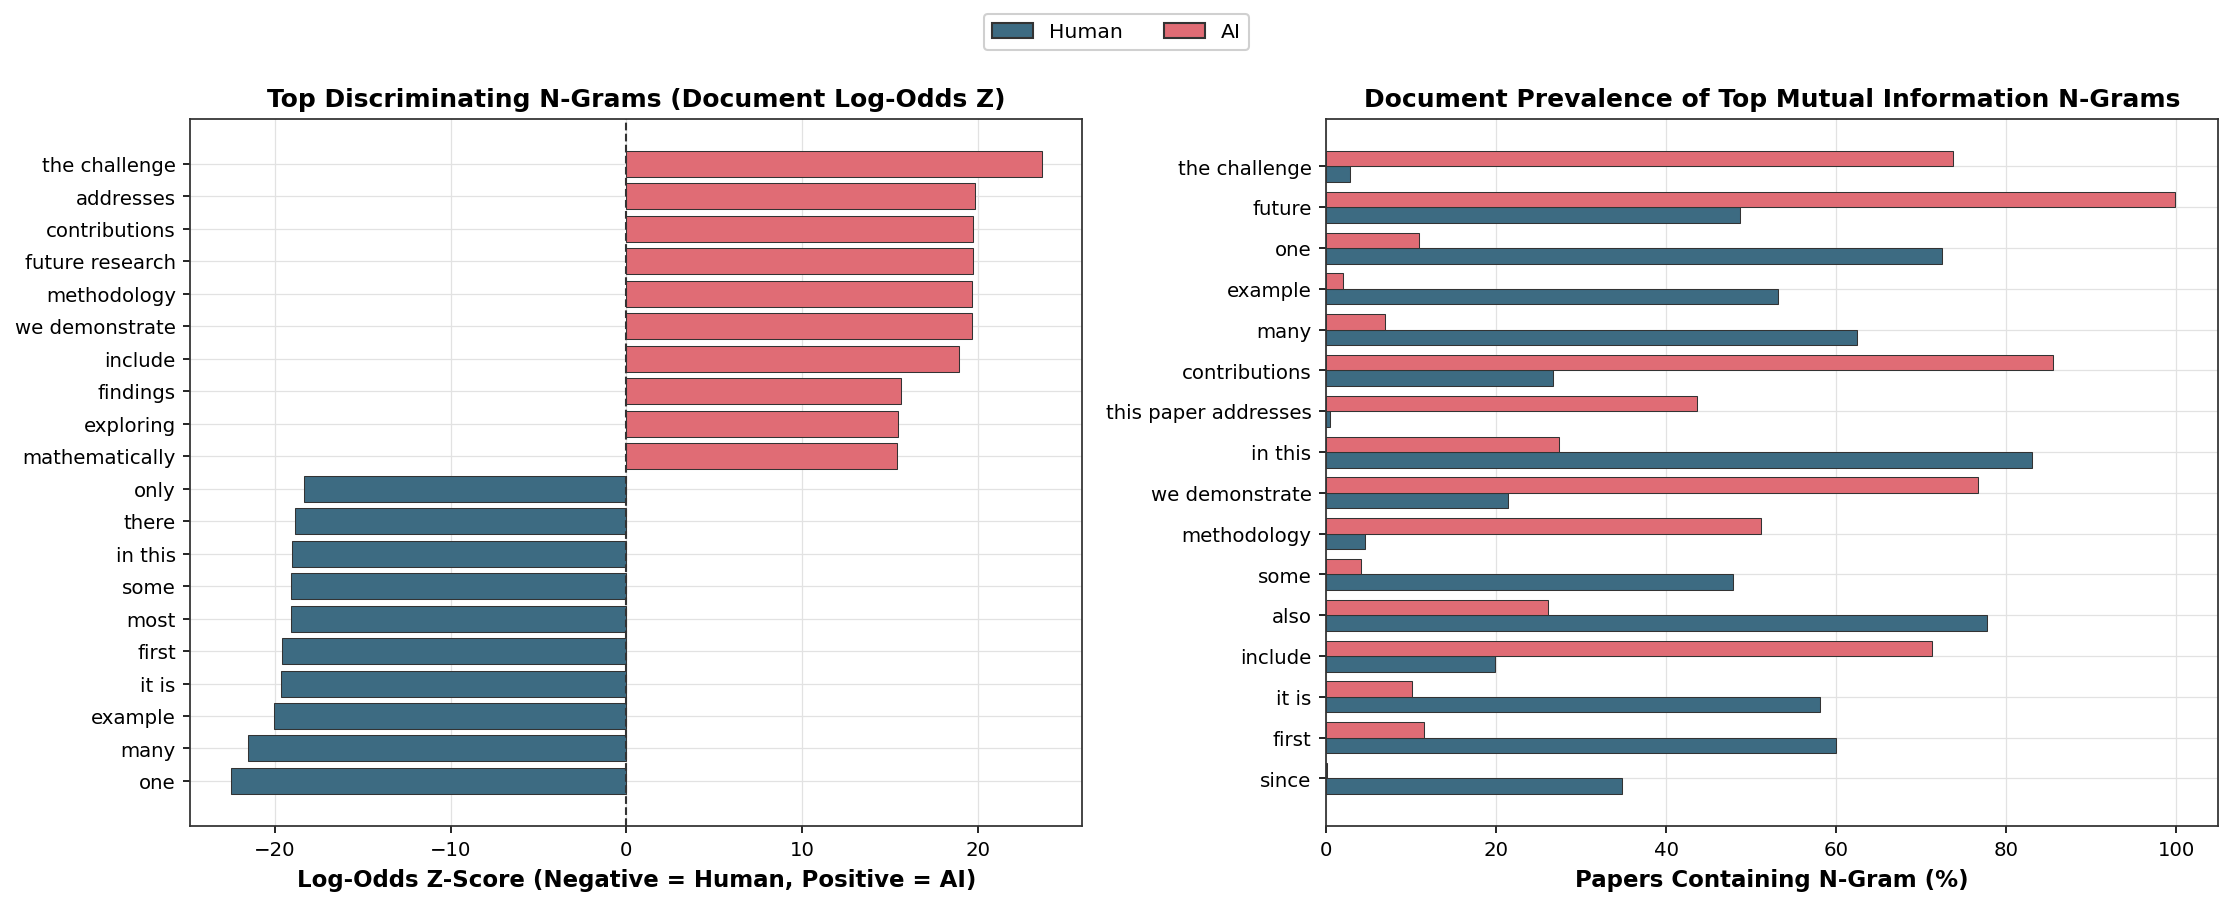

In [36]:
#CELL 3.5 - EXTRACT NON-REDUNDANT DISCRIMINATING N-GRAMS BY DOCUMENT INCIDENCE
def deduplicate_overlapping_ngrams(
    df_candidates: pd.DataFrame, stop_set: Set[str], top_k: int = 16
) -> pd.DataFrame:
    """Filter out overlapping sub-phrases and shared content-root duplicates."""
    selected_rows = []
    seen_substrings: List[str] = []
    seen_content_roots: Set[str] = set()
    for _, row in df_candidates.iterrows():
        gram = str(row["ngram"])
        tokens = gram.split()
        content_toks = [t[:6] for t in tokens if t not in stop_set and len(t) >= 4]
        if any((gram in prev or prev in gram) for prev in seen_substrings):
            continue
        if content_toks and any(r in seen_content_roots for r in content_toks):
            continue
        selected_rows.append(row)
        seen_substrings.append(gram)
        seen_content_roots.update(content_toks)
        if len(selected_rows) >= top_k:
            break
    return pd.DataFrame(selected_rows).reset_index(drop=True)

def extract_discriminating_ngrams(
    df: pd.DataFrame,
    ngram_range: Tuple[int, int] = (1, 3),
    min_df: int = 15,
    max_features: int = 15000,
    top_k: int = 16,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Rank unigrams through trigrams by document-incidence Mutual Information and Dirichlet log-odds z-score."""
    vectorizer = CountVectorizer(
        ngram_range=ngram_range,
        min_df=min_df,
        max_features=max_features,
        lowercase=True,
        token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    )
    count_matrix = vectorizer.fit_transform(df["clean_prose_text"].tolist())
    vocab = np.array(vectorizer.get_feature_names_out())
    labels = df["label"].astype(int).to_numpy()

    #compute binary document incidence to prevent document length confounding
    binary_matrix = (count_matrix > 0).astype(np.int8)
    mi_scores = mutual_info_classif(binary_matrix, labels, discrete_features=True, random_state=GLOBAL_SEED)

    hum_mask = labels == 0
    ai_mask = labels == 1
    n_h = max(int(hum_mask.sum()), 1)
    n_a = max(int(ai_mask.sum()), 1)

    h_doc_cnt = np.asarray(binary_matrix[hum_mask].sum(axis=0)).ravel().astype(np.float64)
    a_doc_cnt = np.asarray(binary_matrix[ai_mask].sum(axis=0)).ravel().astype(np.float64)
    hum_doc_freq = h_doc_cnt / n_h
    ai_doc_freq = a_doc_cnt / n_a

    #compute dirichlet smoothed log odds z score on document incidence
    alpha_scale = 0.01 * len(vocab)
    priors = np.maximum(((h_doc_cnt + a_doc_cnt) / (n_h + n_a)) * alpha_scale, 0.5)
    alpha_0 = float(np.sum(priors))
    num_a = a_doc_cnt + priors
    den_a = np.maximum(n_a + alpha_0 - num_a, 1e-9)
    num_h = h_doc_cnt + priors
    den_h = np.maximum(n_h + alpha_0 - num_h, 1e-9)
    log_odds_z = (np.log(num_a / den_a) - np.log(num_h / den_h)) / np.sqrt((1.0 / num_a) + (1.0 / num_h))
    excess_ratio = (ai_doc_freq * 100.0 + 0.5) / (hum_doc_freq * 100.0 + 0.5)

    #filter by two proportion chi square statistical significance with bh fdr
    tot_pos = h_doc_cnt + a_doc_cnt
    tot_neg = (n_h + n_a) - tot_pos
    e_h_pos = tot_pos * (n_h / (n_h + n_a))
    e_a_pos = tot_pos * (n_a / (n_h + n_a))
    e_h_neg = tot_neg * (n_h / (n_h + n_a))
    e_a_neg = tot_neg * (n_a / (n_h + n_a))
    chi2_stat = (
        (h_doc_cnt - e_h_pos) ** 2 / np.maximum(e_h_pos, 1e-9)
        + (a_doc_cnt - e_a_pos) ** 2 / np.maximum(e_a_pos, 1e-9)
        + ((n_h - h_doc_cnt) - e_h_neg) ** 2 / np.maximum(e_h_neg, 1e-9)
        + ((n_a - a_doc_cnt) - e_a_neg) ** 2 / np.maximum(e_a_neg, 1e-9)
    )
    p_adj = apply_bh_fdr(stats.chi2.sf(chi2_stat, df=1))

    df_ngrams = pd.DataFrame({
        "ngram": vocab,
        "n": [len(g.split()) for g in vocab],
        "mi_score": mi_scores,
        "hum_doc_pct": hum_doc_freq * 100.0,
        "ai_doc_pct": ai_doc_freq * 100.0,
        "excess_ratio": excess_ratio,
        "log_odds_z": log_odds_z,
        "p_adj_fdr": p_adj,
        "class_enriched": np.where(log_odds_z > 0, "AI", "Human"),
    })
    df_ngrams = df_ngrams[df_ngrams["p_adj_fdr"] < 0.01].copy()

    stop_set = set(ENGLISH_STOP_WORDS)
    top_mi = deduplicate_overlapping_ngrams(
        df_ngrams.sort_values("mi_score", ascending=False), stop_set, top_k=top_k
    )
    top_ai_unigrams = (
        df_ngrams[(df_ngrams["n"] == 1) & (~df_ngrams["ngram"].isin(stop_set)) & (df_ngrams["log_odds_z"] > 0) & (df_ngrams["ai_doc_pct"] >= 10.0)]
        .sort_values("log_odds_z", ascending=False)
        .head(15)
        .reset_index(drop=True)
    )
    return df_ngrams, top_mi, top_ai_unigrams

df_all_ngrams, df_top_mi_ngrams, df_top_ai_unigrams = extract_discriminating_ngrams(
    df_ling_corpus, ngram_range=(1, 3), min_df=15, max_features=15000, top_k=16
)

print("TOP 16 NON-REDUNDANT DISCRIMINATING N-GRAMS (MUTUAL INFORMATION, P_ADJ_FDR < 0.01)")
print(df_top_mi_ngrams[["ngram", "n", "mi_score", "hum_doc_pct", "ai_doc_pct", "excess_ratio", "class_enriched"]].round(3).to_string(index=False))

print("\nTOP 15 AI-ENRICHED CONTENT UNIGRAMS (DOCUMENT LOG-ODDS Z-SCORE, P_ADJ_FDR < 0.01)")
print(df_top_ai_unigrams[["ngram", "hum_doc_pct", "ai_doc_pct", "excess_ratio", "log_odds_z"]].round(3).to_string(index=False))

#plot top discriminating ngrams and document prevalence with one shared legend
stop_set_plot = set(ENGLISH_STOP_WORDS)
top_ai_plot = deduplicate_overlapping_ngrams(
    df_all_ngrams[df_all_ngrams["log_odds_z"] > 0].sort_values("log_odds_z", ascending=False), stop_set_plot, top_k=10
)
top_hum_plot = deduplicate_overlapping_ngrams(
    df_all_ngrams[df_all_ngrams["log_odds_z"] < 0].sort_values("log_odds_z", ascending=True), stop_set_plot, top_k=10
)
df_ng_plot = pd.concat([top_hum_plot, top_ai_plot]).sort_values("log_odds_z")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.0, 6.1))
colors_ng = [HUMAN_COLOR if z < 0 else AI_COLOR for z in df_ng_plot["log_odds_z"]]
ax1.barh(df_ng_plot["ngram"], df_ng_plot["log_odds_z"], color=colors_ng, edgecolor="#333333", linewidth=0.5)
ax1.axvline(0.0, color="#333333", linewidth=1.0, linestyle="--")
ax1.set_title("Top Discriminating N-Grams (Document Log-Odds Z)")
ax1.set_xlabel("Log-Odds Z-Score (Negative = Human, Positive = AI)")
style_clean_axis(ax1)

y_mi = np.arange(len(df_top_mi_ngrams))
h_bars = df_top_mi_ngrams["hum_doc_pct"].to_numpy()[::-1]
a_bars = df_top_mi_ngrams["ai_doc_pct"].to_numpy()[::-1]
mi_labels = df_top_mi_ngrams["ngram"].to_numpy()[::-1]
bar_h = 0.38
ax2.barh(y_mi - bar_h / 2, h_bars, height=bar_h, color=HUMAN_COLOR, edgecolor="#333333", linewidth=0.5)
ax2.barh(y_mi + bar_h / 2, a_bars, height=bar_h, color=AI_COLOR, edgecolor="#333333", linewidth=0.5)
ax2.set_yticks(y_mi)
ax2.set_yticklabels(mi_labels)
ax2.set_title("Document Prevalence of Top Mutual Information N-Grams")
ax2.set_xlabel("Papers Containing N-Gram (%)")
style_clean_axis(ax2)

ngram_handles = [
    Patch(facecolor=HUMAN_COLOR, edgecolor="#333333", label="Human"),
    Patch(facecolor=AI_COLOR, edgecolor="#333333", label="AI"),
]
fig.legend(
    handles=ngram_handles, loc="upper center", ncol=2, frameon=True,
    facecolor="white", edgecolor="#CCCCCC", fontsize=9.8, bbox_to_anchor=(0.5, 0.995),
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### Analysis

Measuring phrase incidence across papers (one count per paper, removing length bias) separates `AI` template habits from genuine human exposition:

- **`AI` relies on generic framing phrases:** `"the challenge"` appears in `73.7%` of `AI` papers vs. `2.8%` of `Human` papers, `"contributions"` in `85.5%` vs. `26.7%`, `"methodology"` in `51.1%` vs. `4.6%`, and `"this paper addresses"` in `43.6%` vs. `0.5%`.
- **`Human` authors use concrete reasoning words:** `"one"` (`72.5%` vs. `11.0%`), `"many"` (`62.4%` vs. `6.9%`), `"example"` (`53.1%` vs. `1.9%`), and `"since"` (`34.8%` vs. `0.1%`).

Because common single words like `"future"` or `"contributions"` still appear in `26.7%` to `48.7%` of real human papers, banning or flagging individual words creates false positives. Effective screening and modeling need combinations of rigid multi-word templates (`"the challenge"`, `"this paper addresses"`) alongside the lack of human qualifying markers.

## 3.6 Longitudinal Excess Vocabulary Bridge Across All 13,325 Collected Papers (2015 to 2025)

Building on excess-vocabulary methodologies [4, 5], I test whether the AI-enriched lexical markers discovered from the synthetic corpus in Section 3.5 also surged across **all $13{,}325$ real conference papers** collected in [preprocessed_corpus.jsonl.gz](https://github.com/gustavofcunha/deep-learning-for-nlp-project/blob/main/data/processed/preprocessed_corpus.jsonl.gz) (spanning 2015 to 2025 across ACL, ICLR, ICML, and NeurIPS, excluding synthetic AI texts):
1. **Synthetic-Discovered AI Terms:** The top AI-enriched content unigrams identified empirically in Section 3.5.
2. **Literature Benchmark Excess Markers:** Canonical LLM style words reported in prior studies [4, 5] (`delve`, `delves`, `delving`, `showcasing`, `underscores`, `intricate`, `notably`, `crucial`, `pivotal`, `comprehensive`, `landscape`, `foster`, `leveraging`, `harnessing`).

I compare the pre-2020 baseline ($5{,}462$ real papers, 2015 to 2019) against the post-ChatGPT cohort ($3{,}815$ real papers, 2023 to 2025) using two-sided **Fisher exact tests** (`scipy.stats.fisher_exact`) with **Benjamini-Hochberg FDR** correction, pruning any term that is non-significant ($p_{\text{FDR}} \ge 0.05$) or non-increasing.

Evaluated all 13,325 real collected papers in preprocessed_corpus.jsonl.gz (Pre-2020 baseline: 5,462 papers; 2020-2022 transition: 4,048 papers; Post-2023: 3,815 papers).
Pruned non-significant or non-increasing terms (p_adj_fdr >= 0.05 or abs_excess_pct <= 0): ['include', 'mathematically', 'future', 'formalized']

SIGNIFICANT LONGITUDINAL EXCESS VOCABULARY SHIFTS (PRE-2020 VS POST-2023, P_ADJ_FDR < 0.05)
         term               source  pre2020_pct  post2023_pct  abs_excess_pct  rel_ratio  p_value  p_adj_fdr
      address Synthetic-Discovered       24.844        42.149          17.305      1.696     0.00      0.000
comprehensive Literature-Benchmark        4.138        20.000          15.862      4.824     0.00      0.000
      crucial Literature-Benchmark       10.729        26.239          15.510      2.444     0.00      0.000
contributions Synthetic-Discovered       27.115        41.992          14.878      1.548     0.00      0.000
  demonstrate Synthetic-Discovered       40.26

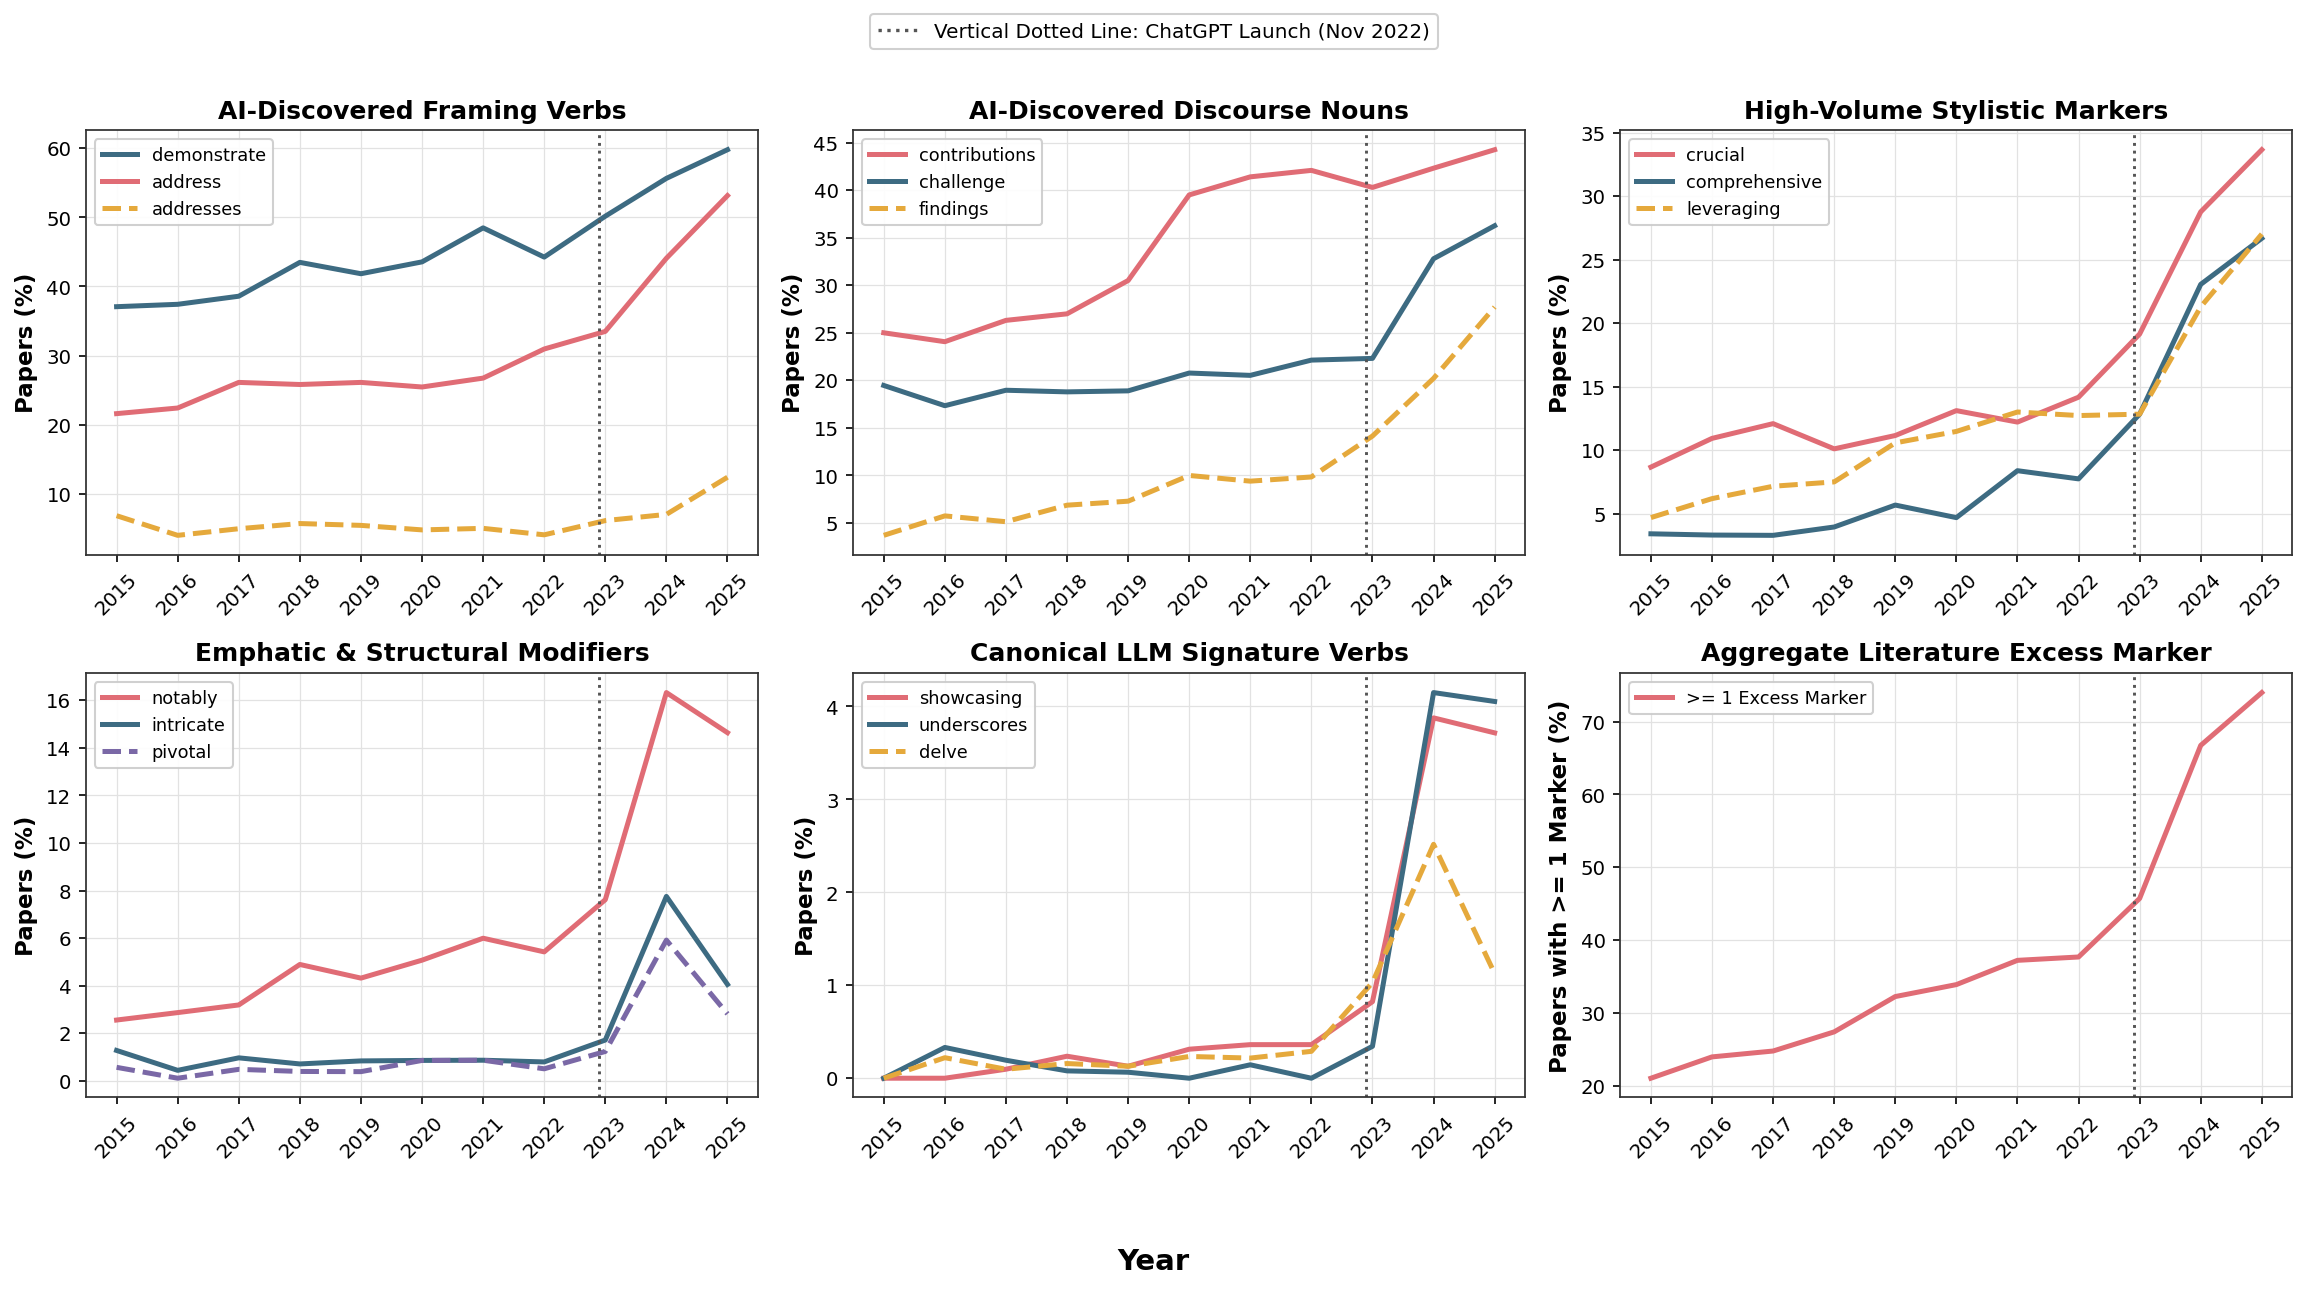

In [37]:
#CELL 3.6 - TRACE SIGNIFICANT LONGITUDINAL EXCESS VOCABULARY ACROSS ALL 13325 REAL PAPERS
LITERATURE_EXCESS_WORDS: List[str] = [
    "delve", "delves", "delving", "showcasing", "underscores",
    "intricate", "notably", "crucial", "pivotal", "comprehensive",
    "landscape", "foster", "leveraging", "harnessing",
]

def compute_longitudinal_excess_vocabulary(
    df_full: pd.DataFrame, discovered_list: List[str], lit_list: List[str]
) -> Tuple[pd.DataFrame, pd.DataFrame, List[str]]:
    """Measure yearly prevalence across all 13,325 real collected papers and filter significant post-2023 shifts."""
    df_real = df_full[df_full["publication_year"].notna()].copy()
    df_real["publication_year"] = df_real["publication_year"].astype(int)
    df_real["clean_prose_text"] = df_real.apply(assemble_paper_text, axis=1).map(strip_placeholder_tokens)

    target_terms = discovered_list + [t for t in lit_list if t not in discovered_list]
    unique_terms = list(dict.fromkeys(t.lower() for t in target_terms if t.strip()))
    vectorizer = CountVectorizer(
        vocabulary=unique_terms,
        ngram_range=(1, 2),
        lowercase=True,
        token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    )
    term_counts = vectorizer.transform(df_real["clean_prose_text"].tolist())
    term_presence = (term_counts > 0).astype(np.int8).toarray()

    df_presence = pd.DataFrame(term_presence, columns=unique_terms, index=df_real.index)
    df_presence["publication_year"] = df_real["publication_year"]
    df_presence["conference"] = df_real["conference"]

    #compute annual percentage prevalence for each tracked term
    yearly_prevalence = df_presence.groupby("publication_year")[unique_terms].mean() * 100.0
    lit_cols = [t for t in lit_list if t in df_presence.columns]
    if lit_cols:
        yearly_prevalence["any_lit_excess_pct"] = (
            df_presence[lit_cols].max(axis=1).groupby(df_presence["publication_year"]).mean() * 100.0
        )
    else:
        yearly_prevalence["any_lit_excess_pct"] = 0.0

    #test pre 2020 baseline vs post 2023 shift using two sided fisher exact test
    pre_mask = df_presence["publication_year"] <= 2019
    post_mask = df_presence["publication_year"] >= 2023
    n_pre = int(pre_mask.sum())
    n_post = int(post_mask.sum())

    shift_rows: List[Dict[str, Any]] = []
    disc_set = set(discovered_list)
    for term in unique_terms:
        k_pre = int(df_presence.loc[pre_mask, term].sum())
        k_post = int(df_presence.loc[post_mask, term].sum())
        p_pre = k_pre / max(n_pre, 1)
        p_post = k_post / max(n_post, 1)
        table = [[k_post, n_post - k_post], [k_pre, n_pre - k_pre]]
        _, p_val = stats.fisher_exact(table, alternative="two-sided") if (n_pre > 0 and n_post > 0) else (1.0, 1.0)
        shift_rows.append({
            "term": term,
            "source": "Synthetic-Discovered" if term in disc_set else "Literature-Benchmark",
            "pre2020_pct": p_pre * 100.0,
            "post2023_pct": p_post * 100.0,
            "abs_excess_pct": (p_post - p_pre) * 100.0,
            "rel_ratio": (p_post + 1e-4) / (p_pre + 1e-4),
            "p_value": float(p_val),
        })

    df_shift_all = pd.DataFrame(shift_rows)
    df_shift_all["p_adj_fdr"] = apply_bh_fdr(df_shift_all["p_value"].to_numpy())
    df_sig = (
        df_shift_all[(df_shift_all["p_adj_fdr"] < 0.05) & (df_shift_all["abs_excess_pct"] > 0)]
        .sort_values("abs_excess_pct", ascending=False)
        .reset_index(drop=True)
    )
    pruned = df_shift_all[~df_shift_all["term"].isin(df_sig["term"])]["term"].tolist()
    print(
        f"Evaluated all {len(df_real):,} real collected papers in preprocessed_corpus.jsonl.gz "
        f"(Pre-2020 baseline: {n_pre:,} papers; 2020-2022 transition: {len(df_real) - n_pre - n_post:,} papers; Post-2023: {n_post:,} papers)."
    )
    print(f"Pruned non-significant or non-increasing terms (p_adj_fdr >= 0.05 or abs_excess_pct <= 0): {pruned}\n")
    return yearly_prevalence, df_sig, pruned

#combine top data driven ai unigrams with literature benchmark markers
discovered_candidates = df_top_ai_unigrams["ngram"].head(12).tolist()
if "address" not in discovered_candidates:
    discovered_candidates.append("address")

df_yearly_excess, df_excess_shift, pruned_excess_terms = compute_longitudinal_excess_vocabulary(
    df_human_full, discovered_candidates, LITERATURE_EXCESS_WORDS
)

print("SIGNIFICANT LONGITUDINAL EXCESS VOCABULARY SHIFTS (PRE-2020 VS POST-2023, P_ADJ_FDR < 0.05)")
print(df_excess_shift.round(3).to_string(index=False))
print("\nAGGREGATE >=1 LITERATURE EXCESS MARKER BY YEAR (%):")
print(df_yearly_excess["any_lit_excess_pct"].round(1).to_string())

#plot clean 2x3 longitudinal lines without markers and shared event legend
years_all = df_yearly_excess.index.to_numpy()
fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.6))
panel_specs = [
    ("AI-Discovered Framing Verbs", "Papers (%)", [("demonstrate", HUMAN_COLOR, "-"), ("address", AI_COLOR, "-"), ("addresses", "#E5A93C", "--")]),
    ("AI-Discovered Discourse Nouns", "Papers (%)", [("contributions", AI_COLOR, "-"), ("challenge", HUMAN_COLOR, "-"), ("findings", "#E5A93C", "--")]),
    ("High-Volume Stylistic Markers", "Papers (%)", [("crucial", AI_COLOR, "-"), ("comprehensive", HUMAN_COLOR, "-"), ("leveraging", "#E5A93C", "--")]),
    ("Emphatic & Structural Modifiers", "Papers (%)", [("notably", AI_COLOR, "-"), ("intricate", HUMAN_COLOR, "-"), ("pivotal", "#7A68A6", "--")]),
    ("Canonical LLM Signature Verbs", "Papers (%)", [("showcasing", AI_COLOR, "-"), ("underscores", HUMAN_COLOR, "-"), ("delve", "#E5A93C", "--")]),
    ("Aggregate Literature Excess Marker", "Papers with >= 1 Marker (%)", [("any_lit_excess_pct", AI_COLOR, "-")]),
]

for ax, (title, ylabel, series_list) in zip(axes.flat, panel_specs):
    for term_col, col_hex, lstyle in series_list:
        if term_col in df_yearly_excess.columns:
            lbl = ">= 1 Excess Marker" if term_col == "any_lit_excess_pct" else term_col
            ax.plot(years_all, df_yearly_excess[term_col], color=col_hex, linestyle=lstyle, linewidth=2.4, label=lbl)
    ax.axvline(2022.9, color="#555555", linestyle=":", linewidth=1.4)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(ylabel, fontweight="bold")
    ax.set_xticks(years_all)
    style_clean_axis(ax, rotate_xticks=45)
    ax.legend(loc="upper left", fontsize=8.5)

fig.legend(
    handles=[Line2D([0], [0], color="#555555", linestyle=":", linewidth=1.6, label="Vertical Dotted Line: ChatGPT Launch (Nov 2022)")],
    loc="upper center", ncol=1, frameon=True, facecolor="white", edgecolor="#CCCCCC",
    fontsize=9.6, bbox_to_anchor=(0.5, 0.995),
)
fig.supxlabel("Year", fontsize=14, fontweight="bold", y=0.01)
plt.tight_layout(rect=[0, 0.04, 1, 0.94])
plt.show()

### Analysis

Tracking the Section 3.5 words across all `13,325` real published papers (`2015` to `2025`) filters out prompt artifacts (`include`, `mathematically`, `future`, `formalized`) and isolates `22` markers that jumped significantly after ChatGPT launched ($p < 0.05$):

- **Sustained framing shifts:** Synthetic-discovered verbs and nouns (`address`: `24.8%` to `42.1%`; `contributions`: `27.1%` to `42.0%`; `demonstrate`: `40.3%` to `54.5%`; `challenge`: `18.7%` to `29.6%`) and broad modifiers (`comprehensive`: `4.1%` to `20.0%`; `crucial`: `10.7%` to `26.2%`; `leveraging`: `7.7%` to `19.4%`) kept climbing steadily through `2025`.
- **Buzzword turnover:** Hyped markers like `delve`, `intricate`, and `pivotal` peaked sharply in `2024` and partially receded in `2025`, yet the share of real papers containing at least one benchmark excess marker climbed from `21.0%` (`2015`) and `37.7%` (`2022`) to `66.7%` (`2024`) and `74.0%` (`2025`).

Real AI/NLP proceedings are rapidly converging toward the lexical framing and stylistic patterns of synthetic text. Because viral buzzwords like `delve` fade quickly once authors avoid them, reliable longitudinal tracking must rely on aggregate marker ensembles and deeper syntactic features rather than single hyped words.

# References

[1] Shaib, C., Elazar, Y., Li, J. J., & Wallace, B. C. (2024). Detection and Measurement of Syntactic Templates in Generated Text. In *Proceedings of the 2024 Conference on Empirical Methods in Natural Language Processing (EMNLP 2024)*, pp. 6416-6431. Association for Computational Linguistics. DOI: `10.18653/v1/2024.emnlp-main.368` (arXiv:2407.00211). https://aclanthology.org/2024.emnlp-main.368/

[2] Terčon, L., & Dobrovoljc, K. (2025). Linguistic Characteristics of AI-Generated Text: A Survey. *arXiv preprint arXiv:2510.05136*. https://arxiv.org/abs/2510.05136

[3] Monroe, B. L., Colaresi, M. P., & Quinn, K. M. (2008). Fightin' Words: Lexical Feature Selection and Evaluation for Identifying the Content of Political Conflict. *Political Analysis*, 16(4), 372-403. DOI: `10.1093/pan/mpn018`.

[4] Kobak, D., González-Márquez, R., Horvát, E.-Á., & Lause, J. (2025). Delving into LLM-assisted writing in biomedical publications through excess vocabulary. *Science Advances*, 11(27), eadt3813. DOI: `10.1126/sciadv.adt3813` (original preprint: *arXiv:2406.07016*, 2024). https://www.science.org/doi/10.1126/sciadv.adt3813

[5] Liang, W., Zhang, Y., Wu, Z., Lepp, H., Ji, W., Zhao, X., Cao, H., Liu, S., He, S., Huang, Z., Yang, D., Potts, C., Manning, C. D., & Zou, J. Y. (2024). Mapping the Increasing Use of LLMs in Scientific Papers. *arXiv preprint arXiv:2404.01268*. https://arxiv.org/abs/2404.01268